# Exploratory data analysis: booking behavior and cancellation patterns

This notebook extends the initial profiling and claim checks with visual, business-oriented exploration. Each section calculates a summary first, displays it, and then plots the same result. It is descriptive only: it does not select model features or train a model.


In [151]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

SRC_DIR = Path.cwd().parent / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
import data

plt.style.use("seaborn-v0_8-whitegrid")
bookings = data.read_raw()
bookings["arrival_date"] = data.arrival_date(bookings)
bookings["nights"] = bookings["stays_in_weekend_nights"] + bookings["stays_in_week_nights"]
bookings["arrival_month"] = bookings["arrival_date"].dt.month
bookings["arrival_month_name"] = bookings["arrival_date"].dt.strftime("%b")
print(f"Loaded {len(bookings):,} bookings")


Loaded 119,390 bookings


## 1. When are the hotels busiest?

Monthly booking volume helps show seasonal demand. We calculate monthly arrivals overall and by hotel before plotting them.


In [152]:
monthly_volume = bookings.groupby(["arrival_date", "hotel"]).size().unstack(fill_value=0)
monthly_volume = monthly_volume.resample("MS").sum()
print(monthly_volume.describe().round(1))
display(monthly_volume.head())


hotel  City Hotel  Resort Hotel
count        26.0          26.0
mean       3051.2        1540.8
std         911.7         251.0
min        1235.0         884.0
25%        2478.5        1379.0
50%        3254.5        1564.5
75%        3647.2        1751.0
max        4556.0        1984.0


hotel,City Hotel,Resort Hotel
arrival_date,,
2015-07-01,1398,1378
2015-08-01,2480,1409
2015-09-01,3529,1585
2015-10-01,3386,1571
2015-11-01,1235,1105


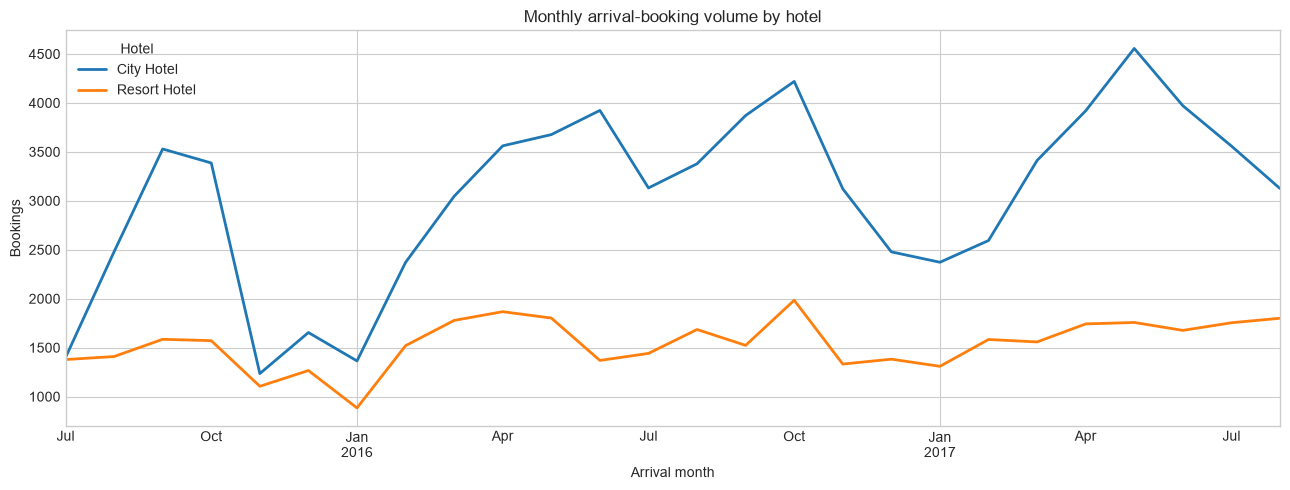

In [153]:
fig, ax = plt.subplots(figsize=(13, 5))
monthly_volume.plot(ax=ax, linewidth=2)
ax.set_title("Monthly arrival-booking volume by hotel")
ax.set_xlabel("Arrival month")
ax.set_ylabel("Bookings")
ax.legend(title="Hotel")
fig.tight_layout()
plt.show()


## 2. Does cancellation behavior change by arrival month?

The monthly cancellation rate is more useful than volume alone because the overbooking problem depends on how many bookings fail to arrive.


In [154]:
monthly_cancellation = bookings.groupby(["arrival_month", "hotel"])["is_canceled"].mean().unstack() * 100
monthly_cancellation.index = [pd.Timestamp(year=2000, month=int(month), day=1).strftime("%b") for month in monthly_cancellation.index]
print(monthly_cancellation.round(2))


hotel  City Hotel  Resort Hotel
Jan         39.67         14.82
Feb         38.29         25.62
Mar         36.95         22.87
Apr         46.32         29.34
May         44.38         28.77
Jun         44.69         33.07
Jul         40.88         31.40
Aug         40.10         33.45
Sep         42.03         32.37
Oct         42.97         27.51
Nov         38.12         18.92
Dec         42.11         23.83


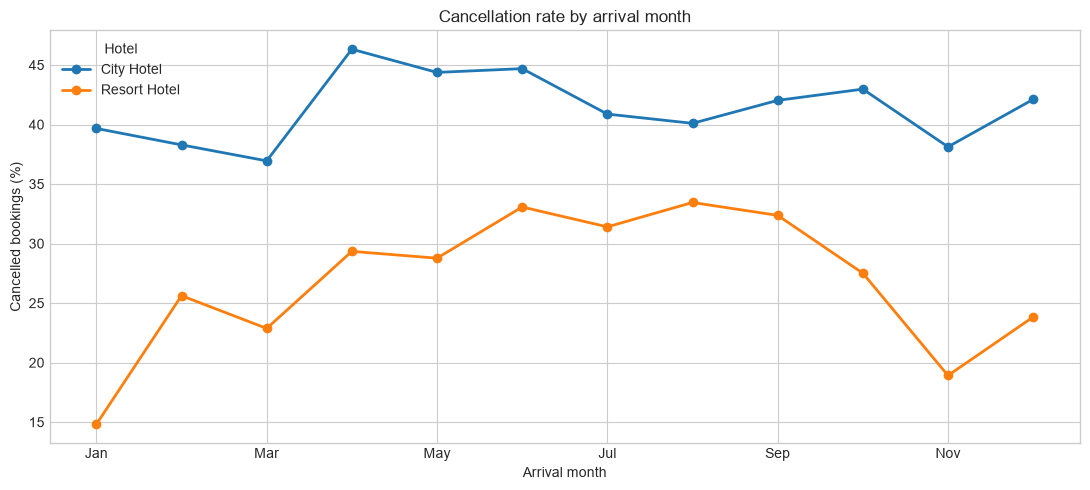

In [155]:
fig, ax = plt.subplots(figsize=(11, 5))
monthly_cancellation.plot(ax=ax, marker="o", linewidth=2)
ax.set_title("Cancellation rate by arrival month")
ax.set_xlabel("Arrival month")
ax.set_ylabel("Cancelled bookings (%)")
ax.legend(title="Hotel")
fig.tight_layout()
plt.show()


## 3. How does booking lead time relate to cancellations?

We group bookings by how far ahead they were made. This shows whether long-lead bookings behave differently from last-minute bookings.


In [156]:
lead_bins = [-1, 7, 30, 90, 180, 365, float("inf")]
lead_labels = ["0-7", "8-30", "31-90", "91-180", "181-365", "366+"]
bookings["lead_time_band"] = pd.cut(bookings["lead_time"], bins=lead_bins, labels=lead_labels)
lead_summary = bookings.groupby("lead_time_band", observed=False)["is_canceled"].agg(bookings="size", cancellation_rate="mean")
lead_summary["cancellation_rate_pct"] = lead_summary["cancellation_rate"] * 100
display(lead_summary.round(3))


,bookings,cancellation_rate,cancellation_rate_pct
lead_time_band,,,
0-7,19746,0.096,9.632
8-30,18960,0.279,27.864
31-90,29553,0.377,37.698
91-180,26439,0.447,44.710
181-365,21544,0.555,55.454
366+,3148,0.677,67.662


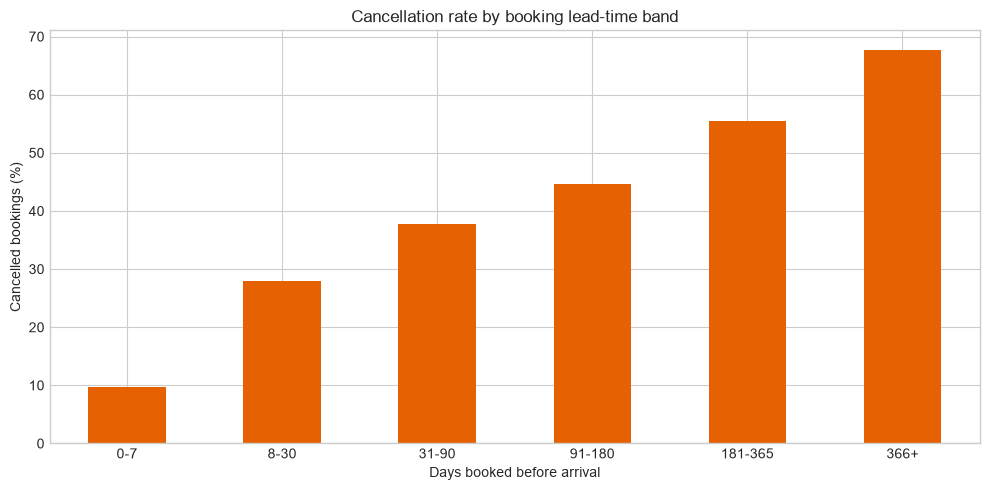

In [157]:
fig, ax = plt.subplots(figsize=(10, 5))
lead_summary["cancellation_rate_pct"].plot.bar(ax=ax, color="#e66101")
ax.set_title("Cancellation rate by booking lead-time band")
ax.set_xlabel("Days booked before arrival")
ax.set_ylabel("Cancelled bookings (%)")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()


## 4. What is the typical length of stay?

Length of stay affects booking value and helps explain how different hotel demand patterns may be.


In [158]:
stay_summary = bookings.groupby("hotel")["nights"].agg(bookings="size", mean="mean", median="median", maximum="max")
display(stay_summary.round(2))


,bookings,mean,median,maximum
hotel,,,,
City Hotel,79330,2.98,3.0,57
Resort Hotel,40060,4.32,3.0,69


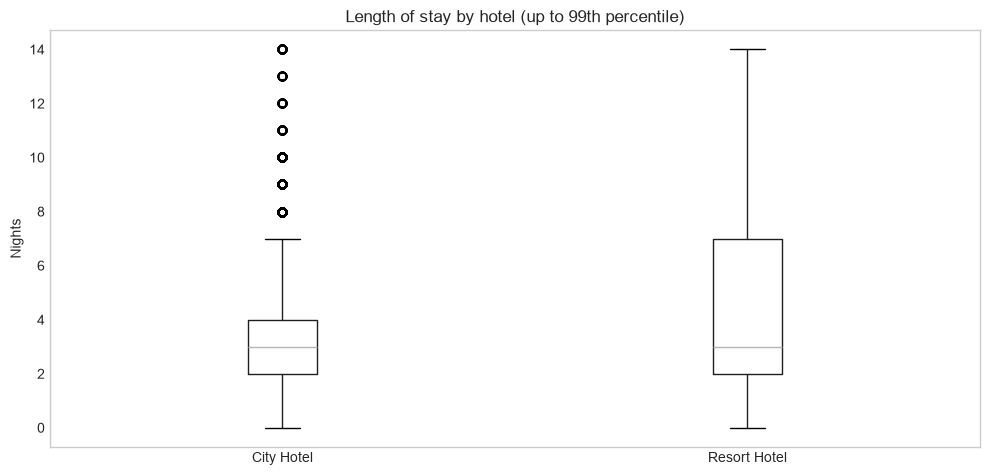

In [159]:
fig, ax = plt.subplots(figsize=(10, 5))
plot_stays = bookings.loc[bookings["nights"] <= bookings["nights"].quantile(0.99)]
plot_stays.boxplot(column="nights", by="hotel", ax=ax, grid=False)
ax.set_title("Length of stay by hotel (up to 99th percentile)")
ax.set_xlabel("")
ax.set_ylabel("Nights")
fig.suptitle("")
fig.tight_layout()
plt.show()


## 5. Which booking channels bring volume and cancellations?

We calculate both booking volume and cancellation rate by distribution channel. A small channel with an extreme rate should not be interpreted without its sample size.


In [160]:
channel_summary = bookings.groupby("distribution_channel")["is_canceled"].agg(bookings="size", cancelled="sum", cancellation_rate="mean").sort_values("bookings", ascending=False)
channel_summary["cancellation_rate_pct"] = channel_summary["cancellation_rate"] * 100
display(channel_summary.round(3))


,bookings,cancelled,cancellation_rate,cancellation_rate_pct
distribution_channel,,,,
TA/TO,97870,40152,0.410,41.026
Direct,14645,2557,0.175,17.460
Corporate,6677,1474,0.221,22.076
GDS,193,37,0.192,19.171
Undefined,5,4,0.800,80.000


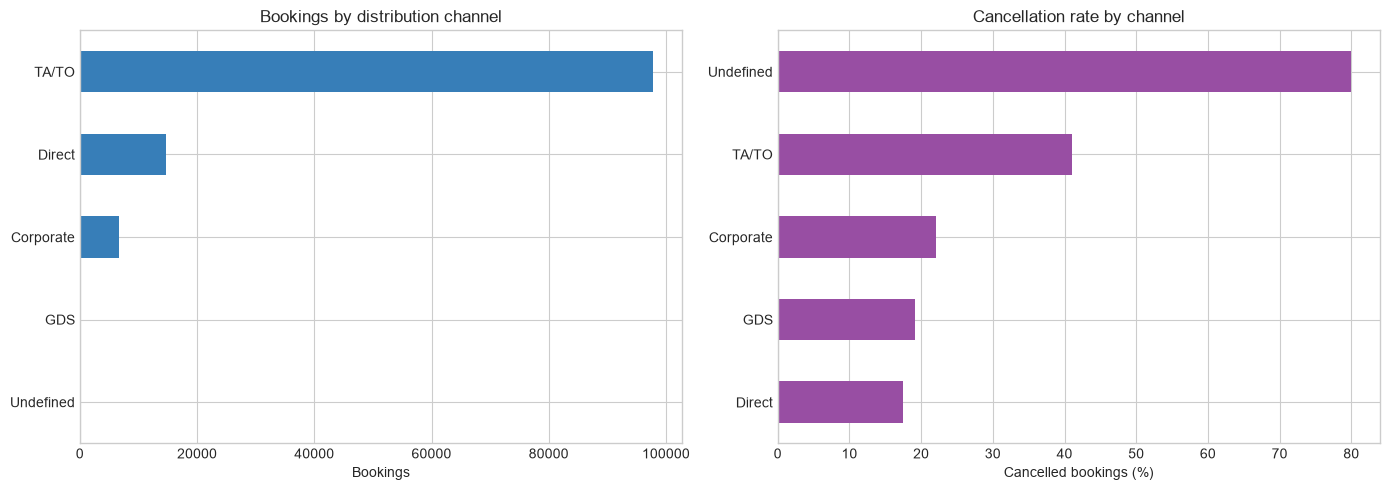

In [161]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
channel_summary.sort_values("bookings")["bookings"].plot.barh(ax=axes[0], color="#377eb8")
axes[0].set_title("Bookings by distribution channel")
axes[0].set_xlabel("Bookings")
axes[0].set_ylabel("")
channel_summary.sort_values("cancellation_rate_pct")["cancellation_rate_pct"].plot.barh(ax=axes[1], color="#984ea3")
axes[1].set_title("Cancellation rate by channel")
axes[1].set_xlabel("Cancelled bookings (%)")
axes[1].set_ylabel("")
fig.tight_layout()
plt.show()


## 6. How does price vary by hotel and cancellation outcome?

ADR is shown descriptively here. It remains a scoring value and its feature-timing treatment is documented separately in the column audit.


In [162]:
adr_summary = bookings.groupby(["hotel", "is_canceled"])["adr"].agg(bookings="size", median="median", mean="mean")
display(adr_summary.round(2))


bookings  median    mean
hotel        is_canceled                          
City Hotel   0               46228    99.9  105.75
             1               33102    99.8  104.69
Resort Hotel 0               28938    72.0   90.79
             1               11122    84.0  105.79

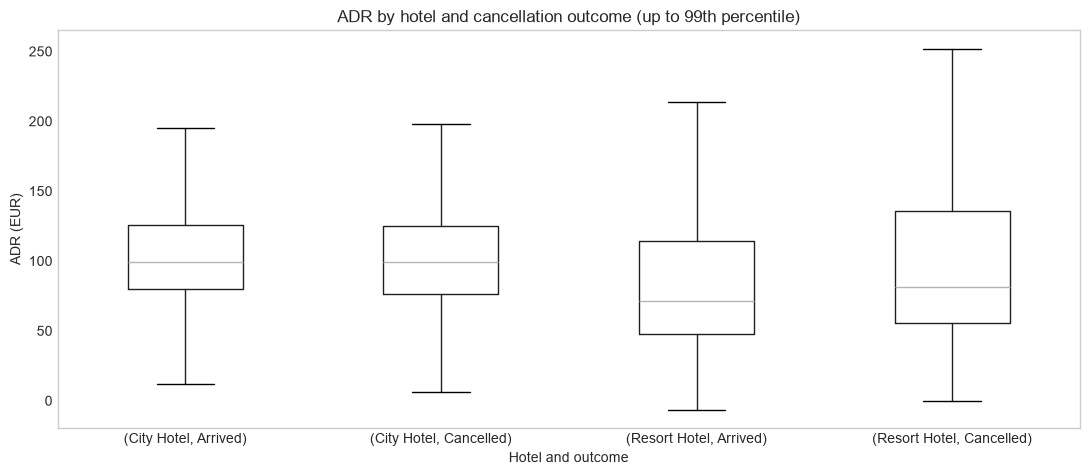

In [163]:
fig, ax = plt.subplots(figsize=(11, 5))
adr_plot = bookings.loc[bookings["adr"] <= bookings["adr"].quantile(0.99)].copy()
adr_plot["outcome"] = adr_plot["is_canceled"].map({0: "Arrived", 1: "Cancelled"})
adr_plot.boxplot(column="adr", by=["hotel", "outcome"], ax=ax, grid=False, showfliers=False)
ax.set_title("ADR by hotel and cancellation outcome (up to 99th percentile)")
ax.set_xlabel("Hotel and outcome")
ax.set_ylabel("ADR (EUR)")
fig.suptitle("")
fig.tight_layout()
plt.show()


## 7. Do special requests relate to cancellations?

This is a descriptive relationship, not a causal conclusion. We calculate the rate and sample size for each request count.


In [164]:
request_summary = bookings.groupby("total_of_special_requests")["is_canceled"].agg(bookings="size", cancellation_rate="mean")
request_summary["cancellation_rate_pct"] = request_summary["cancellation_rate"] * 100
display(request_summary.round(3))


,bookings,cancellation_rate,cancellation_rate_pct
total_of_special_requests,,,
0,70318,0.477,47.720
1,33226,0.220,22.025
2,12969,0.221,22.099
3,2497,0.179,17.861
4,340,0.106,10.588
5,40,0.050,5.000


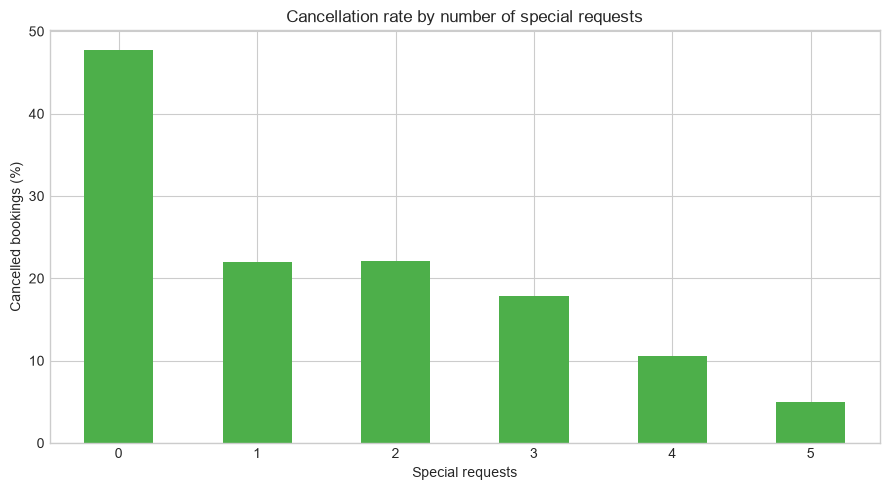

In [165]:
fig, ax = plt.subplots(figsize=(9, 5))
request_summary["cancellation_rate_pct"].plot.bar(ax=ax, color="#4daf4a")
ax.set_title("Cancellation rate by number of special requests")
ax.set_xlabel("Special requests")
ax.set_ylabel("Cancelled bookings (%)")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()


## 8. How does deposit type relate to cancellations?

Deposit type is a useful indicator of booking commitment. We compare both the number of bookings and cancellation rate by hotel so that a high rate in a very small group is not mistaken for a major business pattern.


In [166]:
deposit_summary = bookings.groupby(["hotel", "deposit_type"])["is_canceled"].agg(bookings="size", cancellation_rate="mean")
deposit_summary["cancellation_rate_pct"] = deposit_summary["cancellation_rate"] * 100
display(deposit_summary.sort_values(["hotel", "bookings"], ascending=[True, False]).round(3))


bookings  cancellation_rate  cancellation_rate_pct
hotel        deposit_type                                                    
City Hotel   No Deposit       66442              0.305                 30.469
             Non Refund       12868              0.998                 99.813
             Refundable          20              0.700                 70.000
Resort Hotel No Deposit       38199              0.247                 24.739
             Non Refund        1719              0.960                 95.986
             Refundable         142              0.155                 15.493

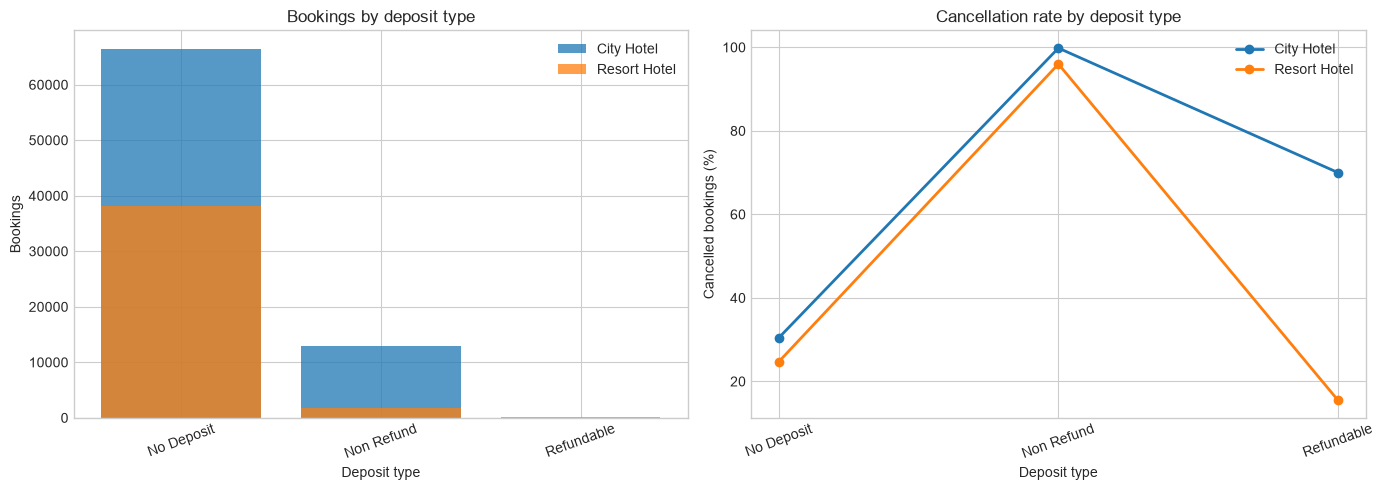

In [167]:
deposit_plot = deposit_summary.reset_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for hotel, group in deposit_plot.groupby("hotel"):
    axes[0].bar(group["deposit_type"], group["bookings"], alpha=0.75, label=hotel)
    axes[1].plot(group["deposit_type"], group["cancellation_rate_pct"], marker="o", linewidth=2, label=hotel)
axes[0].set_title("Bookings by deposit type")
axes[0].set_xlabel("Deposit type")
axes[0].set_ylabel("Bookings")
axes[1].set_title("Cancellation rate by deposit type")
axes[1].set_xlabel("Deposit type")
axes[1].set_ylabel("Cancelled bookings (%)")
for ax in axes:
    ax.legend()
    ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
plt.show()


## 9. Do repeat guests behave differently from new guests?

Repeat-guest status and previous cancellation history provide a view of customer relationship and prior booking behavior. The comparison is descriptive and should not be treated as proof that one causes the other.


In [168]:
guest_history = bookings.assign(
    guest_group=bookings["is_repeated_guest"].map({0: "New guest", 1: "Repeat guest"}),
    prior_cancellation_group=pd.cut(
        bookings["previous_cancellations"],
        bins=[-1, 0, 1, float("inf")],
        labels=["None", "One", "Two or more"],
    ),
)
guest_summary = guest_history.groupby("guest_group", observed=False)["is_canceled"].agg(bookings="size", cancellation_rate="mean")
guest_summary["cancellation_rate_pct"] = guest_summary["cancellation_rate"] * 100
prior_summary = guest_history.groupby("prior_cancellation_group", observed=False)["is_canceled"].agg(bookings="size", cancellation_rate="mean")
prior_summary["cancellation_rate_pct"] = prior_summary["cancellation_rate"] * 100
display(guest_summary.round(3))
display(prior_summary.round(3))


,bookings,cancellation_rate,cancellation_rate_pct
guest_group,,,
New guest,115580,0.378,37.785
Repeat guest,3810,0.145,14.488


,bookings,cancellation_rate,cancellation_rate_pct
prior_cancellation_group,,,
None,112906,0.339,33.906
One,6051,0.944,94.431
Two or more,433,0.527,52.656


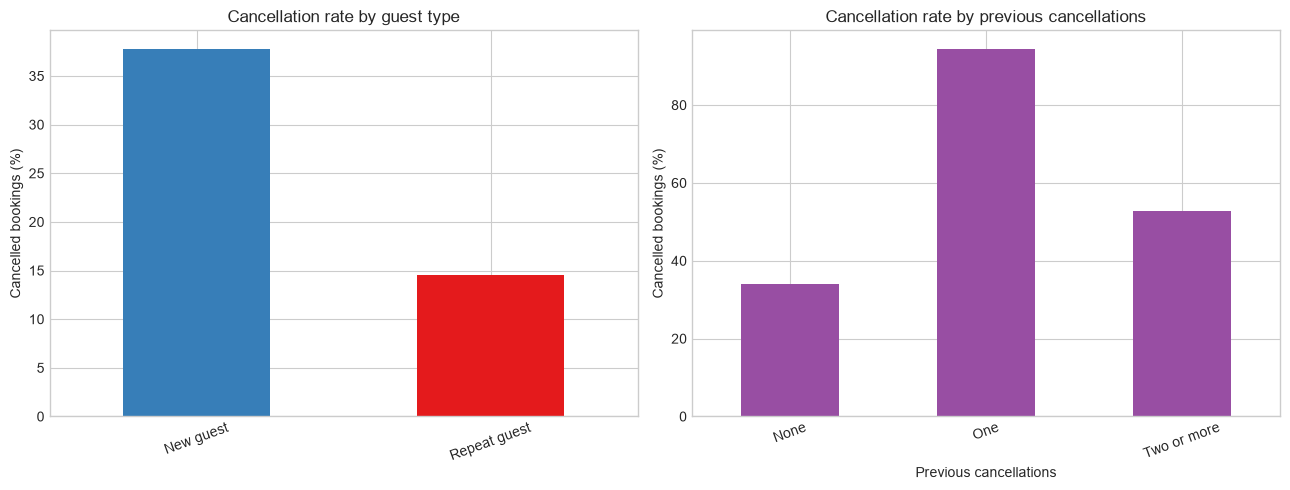

In [169]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
guest_summary["cancellation_rate_pct"].plot.bar(ax=axes[0], color=["#377eb8", "#e41a1c"])
prior_summary["cancellation_rate_pct"].plot.bar(ax=axes[1], color="#984ea3")
axes[0].set_title("Cancellation rate by guest type")
axes[0].set_xlabel("")
axes[1].set_title("Cancellation rate by previous cancellations")
axes[1].set_xlabel("Previous cancellations")
for ax in axes:
    ax.set_ylabel("Cancelled bookings (%)")
    ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
plt.show()


## 10. Does the requested room type match the assigned room type?

A mismatch between reserved and assigned room type can indicate an operational change. We compare matched and mismatched bookings by hotel and outcome, while keeping the chart focused on groups with enough observations.


In [170]:
room_match = bookings.assign(
    room_assignment=bookings["reserved_room_type"].eq(bookings["assigned_room_type"]).map({True: "Matched", False: "Mismatch"})
)
room_match_summary = room_match.groupby(["hotel", "room_assignment"])["is_canceled"].agg(bookings="size", cancellation_rate="mean")
room_match_summary["cancellation_rate_pct"] = room_match_summary["cancellation_rate"] * 100
display(room_match_summary.round(3))


bookings  cancellation_rate  \
hotel        room_assignment                                
City Hotel   Matched             72138              0.453   
             Mismatch             7192              0.058   
Resort Hotel Matched             32335              0.332   
             Mismatch             7725              0.050   

                              cancellation_rate_pct  
hotel        room_assignment                         
City Hotel   Matched                         45.308  
             Mismatch                         5.812  
Resort Hotel Matched                         33.209  
             Mismatch                         4.971

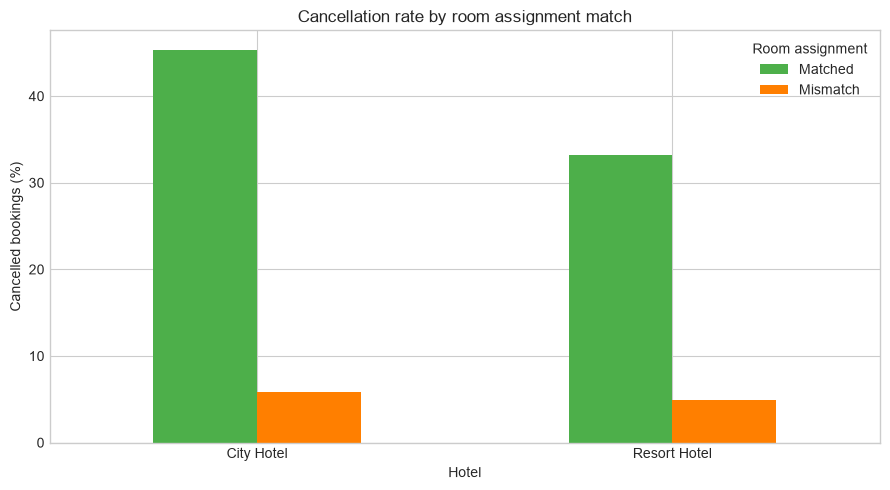

In [171]:
room_match_plot = room_match_summary["cancellation_rate_pct"].unstack()
fig, ax = plt.subplots(figsize=(9, 5))
room_match_plot.plot.bar(ax=ax, color=["#4daf4a", "#ff7f00"])
ax.set_title("Cancellation rate by room assignment match")
ax.set_xlabel("Hotel")
ax.set_ylabel("Cancelled bookings (%)")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Room assignment")
fig.tight_layout()
plt.show()


## 11. Does the mix of weekend and weekday nights matter?

Weekend and weekday nights describe the shape of a stay more precisely than total nights alone. We calculate cancellation rates for common combinations and retain the booking counts for context.


In [172]:
stay_composition = bookings.assign(
    stay_pattern=bookings["stays_in_weekend_nights"].astype(str) + " weekend / " + bookings["stays_in_week_nights"].astype(str) + " weekday"
)
stay_composition_summary = stay_composition.groupby("stay_pattern")["is_canceled"].agg(bookings="size", cancellation_rate="mean")
stay_composition_summary["cancellation_rate_pct"] = stay_composition_summary["cancellation_rate"] * 100
stay_composition_summary = stay_composition_summary.sort_values("bookings", ascending=False).head(12)
display(stay_composition_summary.round(3))


,bookings,cancellation_rate,cancellation_rate_pct
stay_pattern,,,
0 weekend / 2 weekday,17956,0.470,46.987
0 weekend / 1 weekday,16451,0.261,26.108
0 weekend / 3 weekday,11564,0.417,41.724
1 weekend / 2 weekday,8979,0.425,42.477
2 weekend / 5 weekday,8655,0.343,34.304
1 weekend / 1 weekday,7326,0.385,38.548
2 weekend / 2 weekday,6749,0.389,38.865
2 weekend / 1 weekday,6533,0.415,41.512
1 weekend / 3 weekday,6152,0.345,34.477


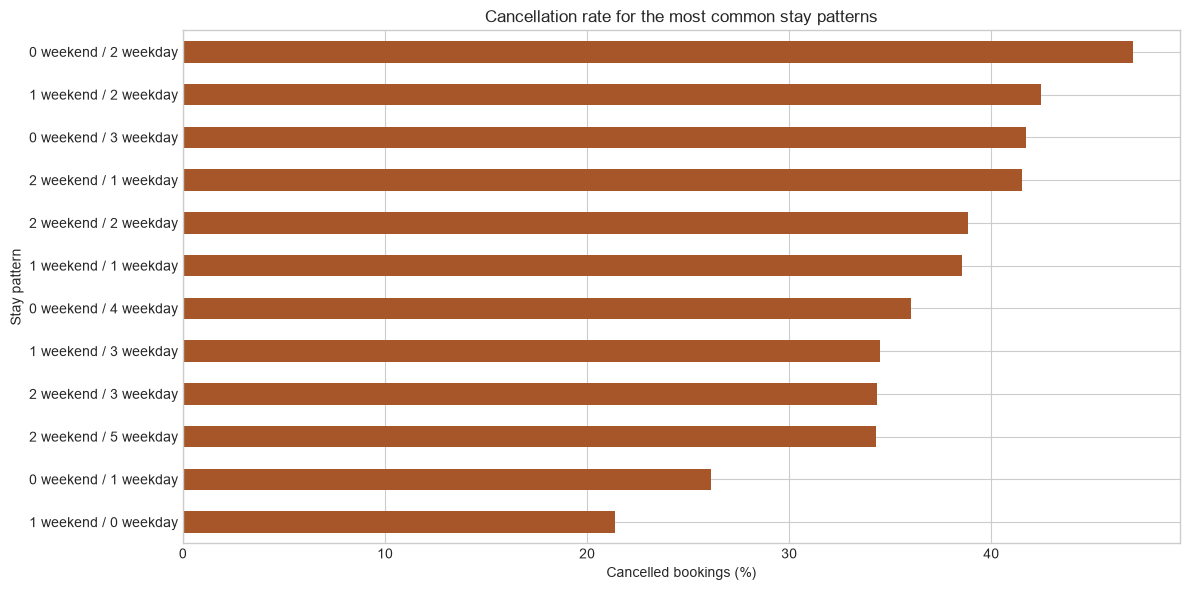

In [173]:
fig, ax = plt.subplots(figsize=(12, 6))
stay_composition_summary.sort_values("cancellation_rate_pct")["cancellation_rate_pct"].plot.barh(ax=ax, color="#a65628")
ax.set_title("Cancellation rate for the most common stay patterns")
ax.set_xlabel("Cancelled bookings (%)")
ax.set_ylabel("Stay pattern")
fig.tight_layout()
plt.show()


## 12. Are booking changes associated with cancellation?

Booking changes capture amendments made before arrival. Comparing cancellation rates across change-count bands helps identify whether stable and frequently amended bookings behave differently.


In [174]:
change_bins = [-1, 0, 1, 2, float("inf")]
change_labels = ["0", "1", "2", "3+"]
bookings["booking_change_band"] = pd.cut(bookings["booking_changes"], bins=change_bins, labels=change_labels)
change_summary = bookings.groupby("booking_change_band", observed=False)["is_canceled"].agg(bookings="size", cancellation_rate="mean")
change_summary["cancellation_rate_pct"] = change_summary["cancellation_rate"] * 100
display(change_summary.round(3))


,bookings,cancellation_rate,cancellation_rate_pct
booking_change_band,,,
0,101314,0.409,40.854
1,12701,0.142,14.227
2,3805,0.201,20.131
3+,1570,0.166,16.561


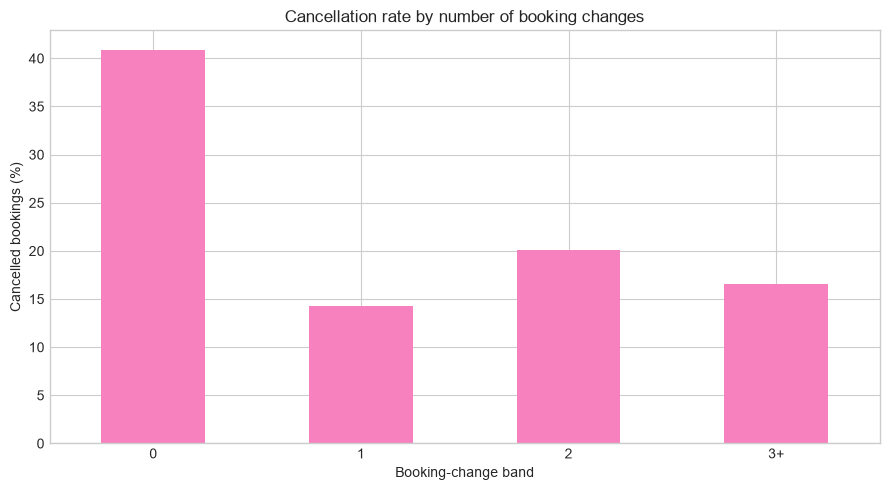

In [175]:
fig, ax = plt.subplots(figsize=(9, 5))
change_summary["cancellation_rate_pct"].plot.bar(ax=ax, color="#f781bf")
ax.set_title("Cancellation rate by number of booking changes")
ax.set_xlabel("Booking-change band")
ax.set_ylabel("Cancelled bookings (%)")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()


## 13. Which arrival weekdays have the most cancellations?

Arrival weekday can reveal differences between weekend and midweek demand. We compare booking volume and cancellation rate by hotel and weekday.


In [176]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_data = bookings.assign(arrival_weekday=bookings["arrival_date"].dt.day_name())
weekday_summary = weekday_data.groupby(["arrival_weekday", "hotel"])["is_canceled"].agg(bookings="size", cancellation_rate="mean")
weekday_summary["cancellation_rate_pct"] = weekday_summary["cancellation_rate"] * 100
weekday_summary = weekday_summary.reindex(pd.MultiIndex.from_product([weekday_order, bookings["hotel"].unique()], names=["arrival_weekday", "hotel"]))
display(weekday_summary.round(3))


bookings  cancellation_rate  \
arrival_weekday hotel                                       
Monday          Resort Hotel      6348              0.256   
                City Hotel       11823              0.386   
Tuesday         Resort Hotel      4872              0.235   
                City Hotel        9127              0.379   
Wednesday       Resort Hotel      4910              0.239   
                City Hotel       11229              0.415   
Thursday        Resort Hotel      6245              0.259   
                City Hotel       13009              0.485   
Friday          Resort Hotel      5676              0.321   
                City Hotel       13955              0.441   
Saturday        Resort Hotel      7062              0.330   
                City Hotel       10993              0.436   
Sunday          Resort Hotel      4947              0.284   
                City Hotel        9194              0.343   

                              cancellation_rate_pct  
arrival_weekday hotel                                
Monday          Resort Hotel                 25.630  
                City Hotel                   38.637  
Tuesday         Resort Hotel                 23.461  
                City Hotel                   37.877  
Wednesday       Resort Hotel                 23.910  
                City Hotel                   41.473  
Thursday        Resort Hotel                 25.893  
                City Hotel                   48.505  
Friday          Resort Hotel                 32.135  
                City Hotel                   44.099  
Saturday        Resort Hotel                 33.008  
                City Hotel                   43.646  
Sunday          Resort Hotel                 28.421  
                City Hotel                   34.348

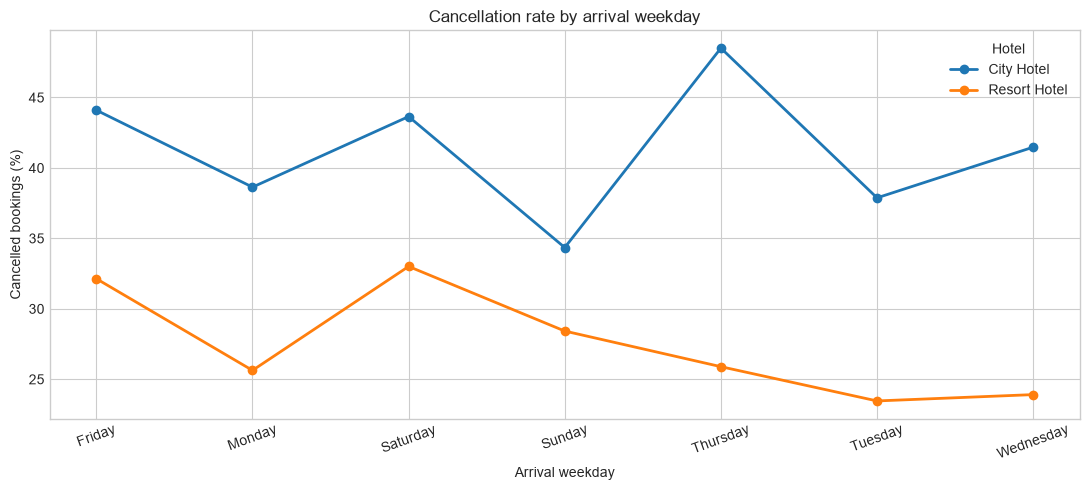

In [177]:
weekday_rates = weekday_summary["cancellation_rate_pct"].unstack()
fig, ax = plt.subplots(figsize=(11, 5))
weekday_rates.plot(ax=ax, marker="o", linewidth=2)
ax.set_title("Cancellation rate by arrival weekday")
ax.set_xlabel("Arrival weekday")
ax.set_ylabel("Cancelled bookings (%)")
ax.tick_params(axis="x", rotation=20)
ax.legend(title="Hotel")
fig.tight_layout()
plt.show()


## 14. Does lead-time behavior differ between the hotels?

The earlier lead-time analysis combined both hotels. This interaction view checks whether the same lead-time bands behave differently at City Hotel and Resort Hotel.


In [178]:
lead_hotel_summary = bookings.groupby(["lead_time_band", "hotel"], observed=False)["is_canceled"].agg(bookings="size", cancellation_rate="mean")
lead_hotel_summary["cancellation_rate_pct"] = lead_hotel_summary["cancellation_rate"] * 100
display(lead_hotel_summary.round(3))


bookings  cancellation_rate  \
lead_time_band hotel                                       
0-7            City Hotel       10808              0.122   
               Resort Hotel      8938              0.065   
8-30           City Hotel       12554              0.309   
               Resort Hotel      6406              0.219   
31-90          City Hotel       20797              0.399   
               Resort Hotel      8756              0.324   
91-180         City Hotel       18223              0.480   
               Resort Hotel      8216              0.374   
181-365        City Hotel       14244              0.627   
               Resort Hotel      7300              0.413   
366+           City Hotel        2704              0.711   
               Resort Hotel       444              0.466   

                             cancellation_rate_pct  
lead_time_band hotel                                
0-7            City Hotel                   12.204  
               Resort Hotel                  6.523  
8-30           City Hotel                   30.906  
               Resort Hotel                 21.901  
31-90          City Hotel                   39.910  
               Resort Hotel                 32.446  
91-180         City Hotel                   47.994  
               Resort Hotel                 37.427  
181-365        City Hotel                   62.721  
               Resort Hotel                 41.274  
366+           City Hotel                   71.117  
               Resort Hotel                 46.622

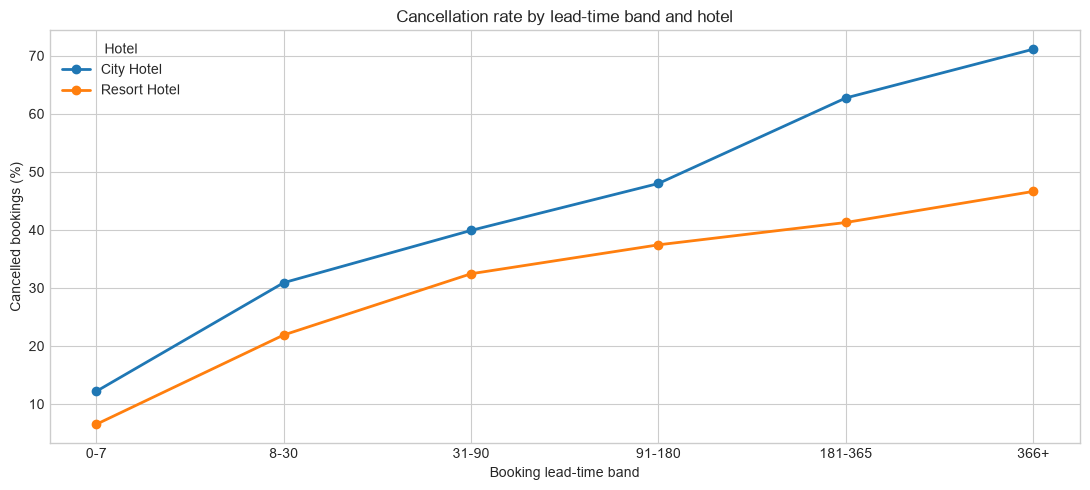

In [179]:
lead_hotel_rates = lead_hotel_summary["cancellation_rate_pct"].unstack()
fig, ax = plt.subplots(figsize=(11, 5))
lead_hotel_rates.plot(ax=ax, marker="o", linewidth=2)
ax.set_title("Cancellation rate by lead-time band and hotel")
ax.set_xlabel("Booking lead-time band")
ax.set_ylabel("Cancelled bookings (%)")
ax.legend(title="Hotel")
fig.tight_layout()
plt.show()


## 15. What happens when a booking spends time on the waiting list?

Waiting-list days describe how long a booking was held before confirmation. We group this operational measure into clear bands and compare cancellation rates.


In [180]:
waiting_bins = [-1, 0, 3, 7, 14, 30, float("inf")]
waiting_labels = ["0", "1-3", "4-7", "8-14", "15-30", "31+"]
bookings["waiting_list_band"] = pd.cut(bookings["days_in_waiting_list"], bins=waiting_bins, labels=waiting_labels)
waiting_summary = bookings.groupby("waiting_list_band", observed=False)["is_canceled"].agg(bookings="size", cancellation_rate="mean")
waiting_summary["cancellation_rate_pct"] = waiting_summary["cancellation_rate"] * 100
display(waiting_summary.round(3))


,bookings,cancellation_rate,cancellation_rate_pct
waiting_list_band,,,
0,115692,0.362,36.187
1-3,76,0.829,82.895
4-7,53,0.302,30.189
8-14,74,0.730,72.973
15-30,389,0.807,80.720
31+,3106,0.616,61.558


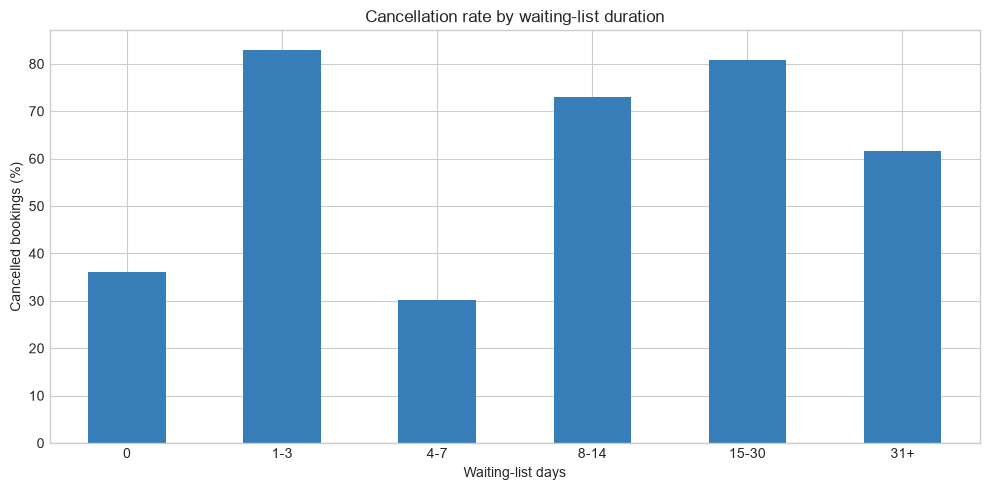

In [181]:
fig, ax = plt.subplots(figsize=(10, 5))
waiting_summary["cancellation_rate_pct"].plot.bar(ax=ax, color="#377eb8")
ax.set_title("Cancellation rate by waiting-list duration")
ax.set_xlabel("Waiting-list days")
ax.set_ylabel("Cancelled bookings (%)")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()


## 16. Are parking requests associated with cancellation?

Parking requests are a simple proxy for practical travel planning. We compare cancellation rates for each request count while retaining booking volume.


In [182]:
parking_summary = bookings.groupby("required_car_parking_spaces")["is_canceled"].agg(bookings="size", cancellation_rate="mean")
parking_summary["cancellation_rate_pct"] = parking_summary["cancellation_rate"] * 100
display(parking_summary.round(3))


,bookings,cancellation_rate,cancellation_rate_pct
required_car_parking_spaces,,,
0,111974,0.395,39.495
1,7383,0.000,0.000
2,28,0.000,0.000
3,3,0.000,0.000
8,2,0.000,0.000


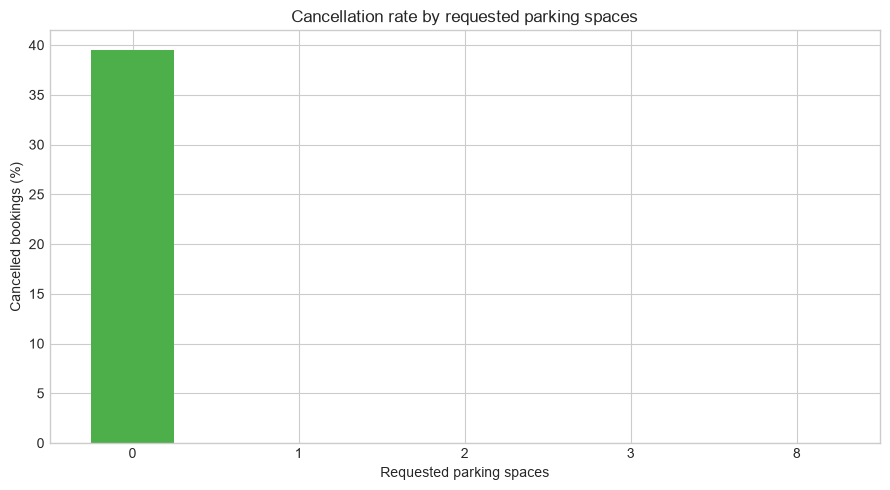

In [183]:
fig, ax = plt.subplots(figsize=(9, 5))
parking_summary["cancellation_rate_pct"].plot.bar(ax=ax, color="#4daf4a")
ax.set_title("Cancellation rate by requested parking spaces")
ax.set_xlabel("Requested parking spaces")
ax.set_ylabel("Cancelled bookings (%)")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()


## 17. Does the presence of family members change cancellation behavior?

We classify bookings as solo, couple, family, or group based on adults, children, babies, and the number of people. This provides a compact view of booking-party structure.


In [184]:
family_data = bookings.assign(
    total_guests=bookings["adults"] + bookings["children"] + bookings["babies"],
)
family_data["party_type"] = "Group"
family_data.loc[(family_data["total_guests"] == 1), "party_type"] = "Solo"
family_data.loc[(family_data["total_guests"] == 2) & (family_data["children"] + family_data["babies"] == 0), "party_type"] = "Couple"
family_data.loc[(family_data["children"] + family_data["babies"] > 0), "party_type"] = "Family"
party_summary = family_data.groupby("party_type")["is_canceled"].agg(bookings="size", cancellation_rate="mean").reindex(["Solo", "Couple", "Family", "Group"])
party_summary["cancellation_rate_pct"] = party_summary["cancellation_rate"] * 100
display(party_summary.round(3))


,bookings,cancellation_rate,cancellation_rate_pct
party_type,,,
Solo,22577,0.290,29.034
Couple,81557,0.398,39.753
Family,9332,0.349,34.923
Group,5924,0.336,33.575


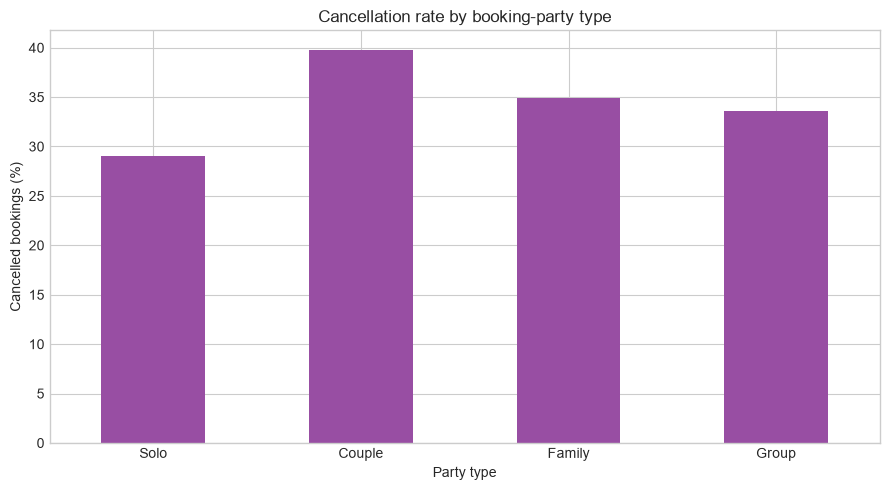

In [185]:
fig, ax = plt.subplots(figsize=(9, 5))
party_summary["cancellation_rate_pct"].plot.bar(ax=ax, color="#984ea3")
ax.set_title("Cancellation rate by booking-party type")
ax.set_xlabel("Party type")
ax.set_ylabel("Cancelled bookings (%)")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()


## 18. Which origin countries contribute the most bookings?

Country counts show where demand comes from. We focus on the 15 largest origin groups, because rates from countries with only a few bookings can be misleading.


In [186]:
country_summary = bookings.groupby("country")["is_canceled"].agg(bookings="size", cancellation_rate="mean")
country_summary["cancellation_rate_pct"] = country_summary["cancellation_rate"] * 100
top_countries = country_summary.sort_values("bookings", ascending=False).head(15)
display(top_countries.round(3))


,bookings,cancellation_rate,cancellation_rate_pct
country,,,
PRT,48590,0.566,56.635
GBR,12129,0.202,20.224
FRA,10415,0.186,18.569
ESP,8568,0.254,25.408
DEU,7287,0.167,16.715
ITA,3766,0.354,35.396
IRL,3375,0.247,24.652
BEL,2342,0.202,20.239
BRA,2224,0.373,37.320


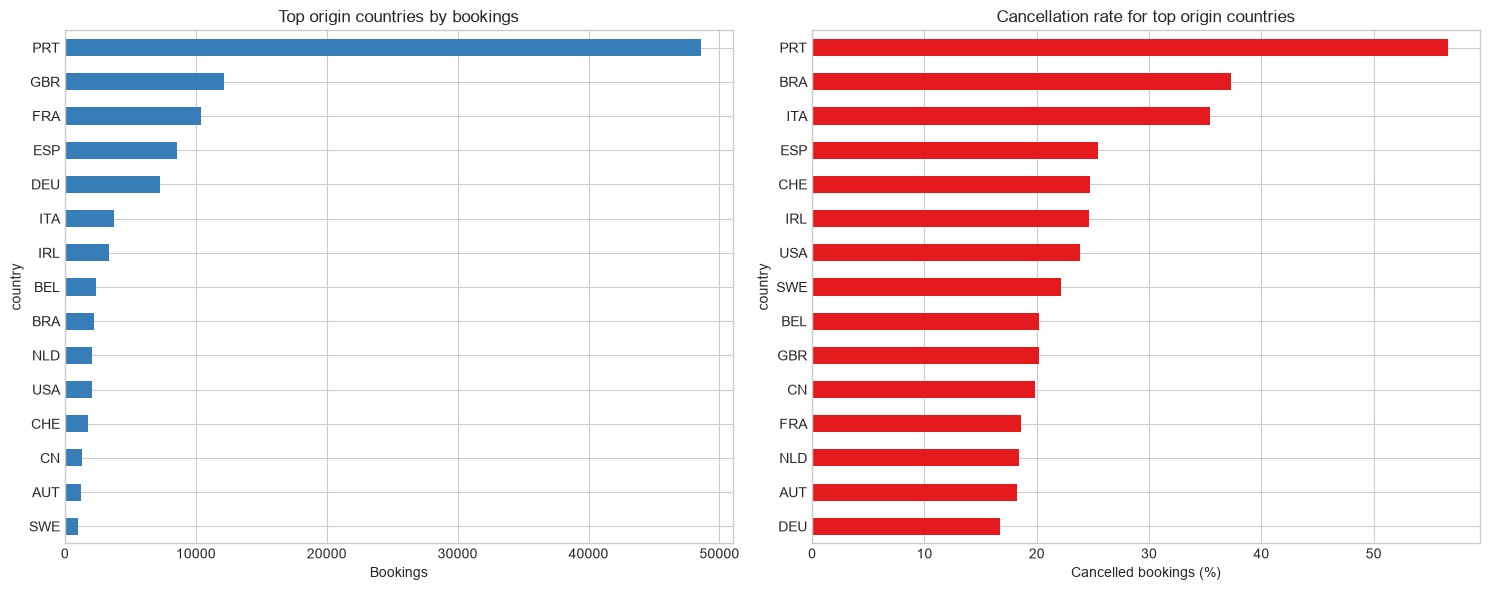

In [187]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
top_countries["bookings"].sort_values().plot.barh(ax=axes[0], color="#377eb8")
top_countries["cancellation_rate_pct"].sort_values().plot.barh(ax=axes[1], color="#e41a1c")
axes[0].set_title("Top origin countries by bookings")
axes[0].set_xlabel("Bookings")
axes[1].set_title("Cancellation rate for top origin countries")
axes[1].set_xlabel("Cancelled bookings (%)")
fig.tight_layout()
plt.show()


## 19. Does market segment behavior differ by hotel?

Market segment can represent different customer acquisition routes. We compare cancellation rates within each hotel and retain booking counts for context.


In [188]:
segment_hotel_summary = bookings.groupby(["market_segment", "hotel"])["is_canceled"].agg(bookings="size", cancellation_rate="mean")
segment_hotel_summary["cancellation_rate_pct"] = segment_hotel_summary["cancellation_rate"] * 100
display(segment_hotel_summary.sort_values("bookings", ascending=False).round(3))


bookings  cancellation_rate  \
market_segment hotel                                       
Online TA      City Hotel       38748              0.374   
               Resort Hotel     17729              0.352   
Offline TA/TO  City Hotel       16747              0.428   
Groups         City Hotel       13975              0.689   
Offline TA/TO  Resort Hotel      7472              0.152   
Direct         Resort Hotel      6513              0.135   
               City Hotel        6093              0.173   
Groups         Resort Hotel      5836              0.424   
Corporate      City Hotel        2986              0.215   
               Resort Hotel      2309              0.152   
Complementary  City Hotel         542              0.118   
Aviation       City Hotel         237              0.219   
Complementary  Resort Hotel       201              0.164   
Undefined      City Hotel           2              1.000   

                             cancellation_rate_pct  
market_segment hotel                                
Online TA      City Hotel                   37.398  
               Resort Hotel                 35.242  
Offline TA/TO  City Hotel                   42.832  
Groups         City Hotel                   68.859  
Offline TA/TO  Resort Hotel                 15.230  
Direct         Resort Hotel                 13.481  
               City Hotel                   17.331  
Groups         Resort Hotel                 42.392  
Corporate      City Hotel                   21.467  
               Resort Hotel                 15.201  
Complementary  City Hotel                   11.808  
Aviation       City Hotel                   21.941  
Complementary  Resort Hotel                 16.418  
Undefined      City Hotel                  100.000

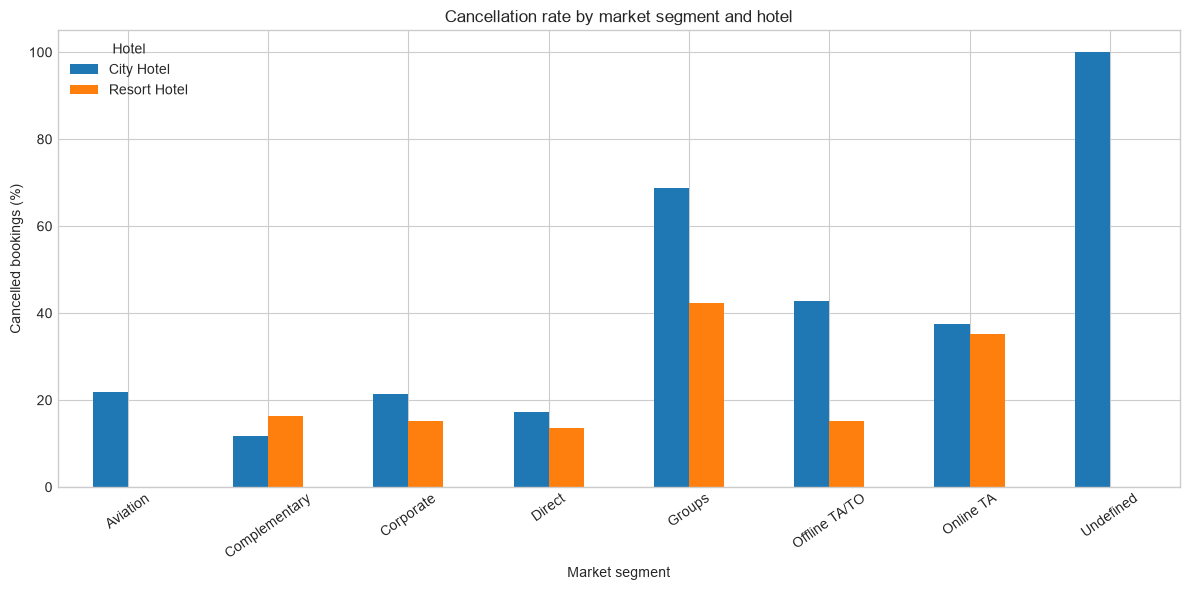

In [189]:
segment_hotel_rates = segment_hotel_summary["cancellation_rate_pct"].unstack()
fig, ax = plt.subplots(figsize=(12, 6))
segment_hotel_rates.plot.bar(ax=ax)
ax.set_title("Cancellation rate by market segment and hotel")
ax.set_xlabel("Market segment")
ax.set_ylabel("Cancelled bookings (%)")
ax.tick_params(axis="x", rotation=35)
ax.legend(title="Hotel")
fig.tight_layout()
plt.show()


## 20. Does cancellation vary across ADR bands?

Grouping ADR into bands helps reveal whether lower- and higher-priced bookings have different cancellation behavior. We use quantile bands so each group has a substantial number of observations.


In [190]:
adr_data = bookings.loc[bookings["adr"] >= 0].copy()
adr_data["adr_band"] = pd.qcut(adr_data["adr"], q=5, duplicates="drop")
adr_band_summary = adr_data.groupby("adr_band", observed=False)["is_canceled"].agg(bookings="size", median_adr="median", cancellation_rate="mean")
adr_band_summary["cancellation_rate_pct"] = adr_band_summary["cancellation_rate"] * 100
display(adr_band_summary.round(3))


,bookings,median_adr,cancellation_rate,cancellation_rate_pct
adr_band,,,,
"(-0.001, 64.0]",23911,0.0,0.350,34.967
"(64.0, 85.0]",24476,0.0,0.342,34.217
"(85.0, 105.0]",23278,0.0,0.393,39.312
"(105.0, 135.0]",24390,0.0,0.392,39.164
"(135.0, 5400.0]",23334,0.0,0.376,37.649


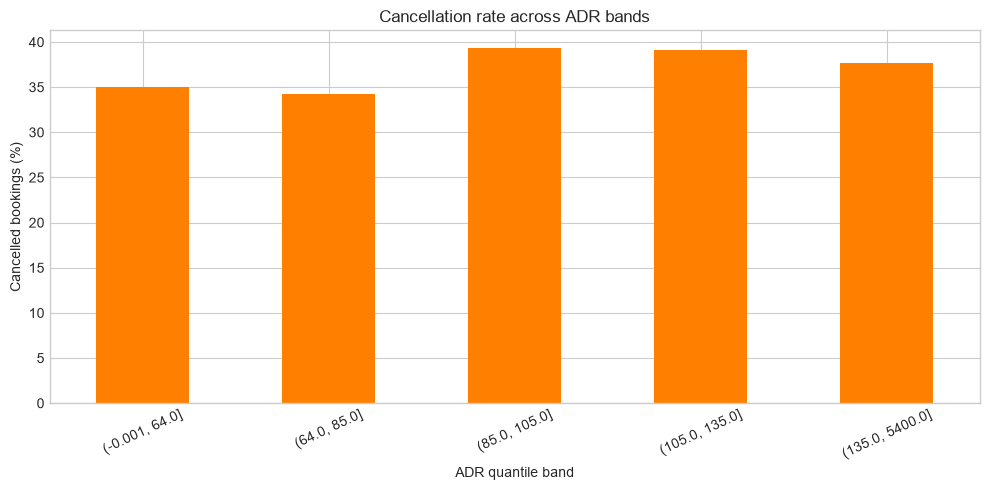

In [191]:
fig, ax = plt.subplots(figsize=(10, 5))
adr_band_summary["cancellation_rate_pct"].plot.bar(ax=ax, color="#ff7f00")
ax.set_title("Cancellation rate across ADR bands")
ax.set_xlabel("ADR quantile band")
ax.set_ylabel("Cancelled bookings (%)")
ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
plt.show()


## 21. Did booking volume and cancellations change by arrival year?

Year-level comparison gives a broad stability check across the dataset period. It is descriptive and does not replace the required chronological train, choose, and proof evaluation.


In [192]:
year_summary = bookings.assign(arrival_year=bookings["arrival_date"].dt.year).groupby("arrival_year")["is_canceled"].agg(bookings="size", cancellation_rate="mean")
year_summary["cancellation_rate_pct"] = year_summary["cancellation_rate"] * 100
display(year_summary.round(3))


,bookings,cancellation_rate,cancellation_rate_pct
arrival_year,,,
2015,21996,0.370,37.016
2016,56707,0.359,35.863
2017,40687,0.387,38.698


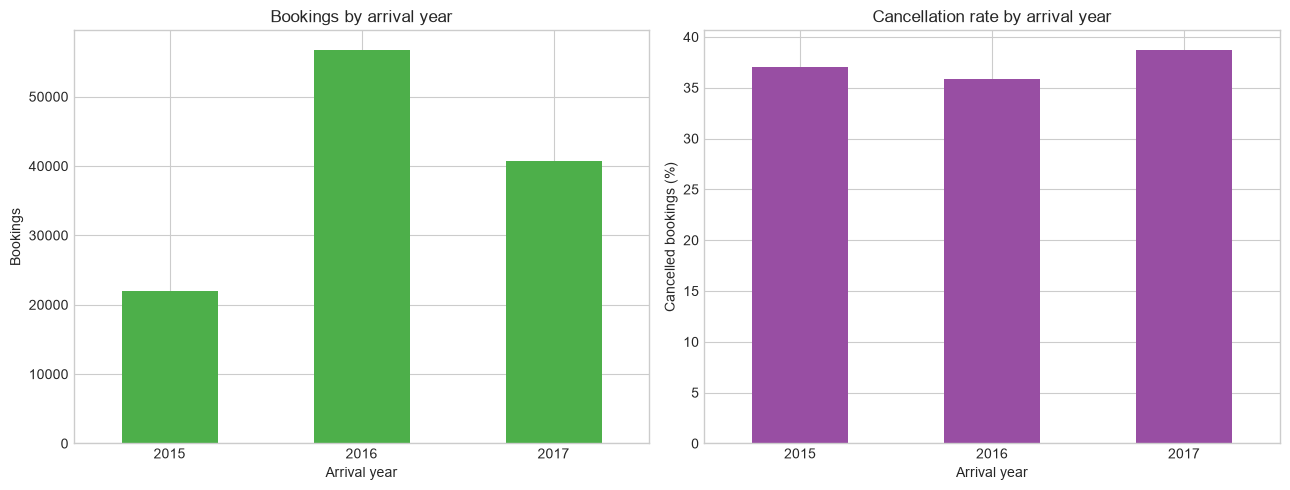

In [193]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
year_summary["bookings"].plot.bar(ax=axes[0], color="#4daf4a")
year_summary["cancellation_rate_pct"].plot.bar(ax=axes[1], color="#984ea3")
axes[0].set_title("Bookings by arrival year")
axes[0].set_xlabel("Arrival year")
axes[0].set_ylabel("Bookings")
axes[1].set_title("Cancellation rate by arrival year")
axes[1].set_xlabel("Arrival year")
axes[1].set_ylabel("Cancelled bookings (%)")
for ax in axes:
    ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()


## 22. Cancellation rate by hotel and month

We compare monthly cancellation rates within each hotel and use a heatmap to highlight high-risk hotel-month combinations.


bookings  cancellation_rate  cancellation_rate_pct
arrival_month hotel                                                           
1             City Hotel        3736              0.397                 39.668
              Resort Hotel      2193              0.148                 14.820
2             City Hotel        4965              0.383                 38.288
              Resort Hotel      3103              0.256                 25.620
3             City Hotel        6458              0.369                 36.946
              Resort Hotel      3336              0.229                 22.872
4             City Hotel        7480              0.463                 46.324
              Resort Hotel      3609              0.293                 29.343
5             City Hotel        8232              0.444                 44.376
              Resort Hotel      3559              0.288                 28.772
6             City Hotel        7894              0.447                 44.692
              Resort Hotel      3045              0.331                 33.071
7             City Hotel        8088              0.409                 40.875
              Resort Hotel      4573              0.314                 31.402
8             City Hotel        8983              0.401                 40.098
              Resort Hotel      4894              0.334                 33.449
9             City Hotel        7400              0.420                 42.027
              Resort Hotel      3108              0.324                 32.368
10            City Hotel        7605              0.430                 42.972
              Resort Hotel      3555              0.275                 27.511
11            City Hotel        4357              0.381                 38.123
              Resort Hotel      2437              0.189                 18.917
12            City Hotel        4132              0.421                 42.110
              Resort Hotel      2648              0.238                 23.829

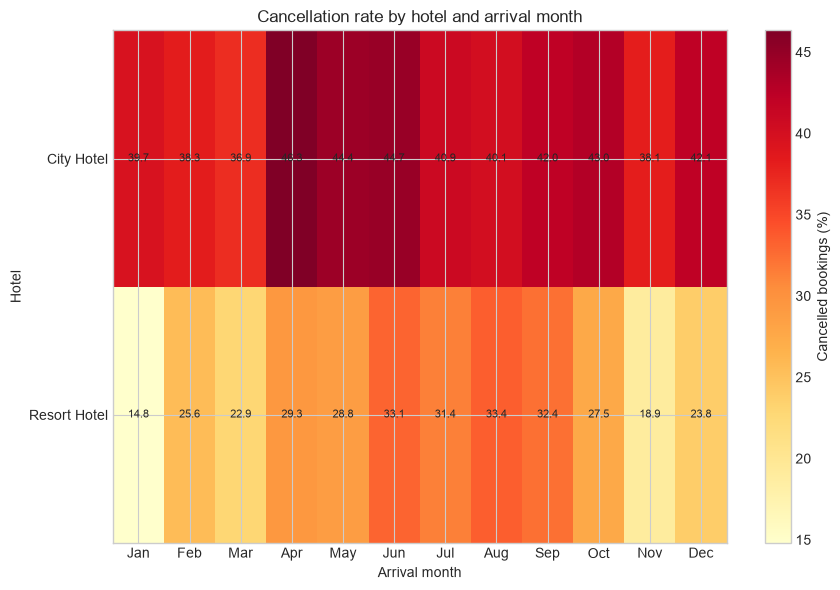

In [194]:
month_hotel = bookings.groupby(["arrival_month", "hotel"])["is_canceled"].agg(bookings="size", cancellation_rate="mean")
month_hotel["cancellation_rate_pct"] = month_hotel["cancellation_rate"] * 100
month_hotel_rates = month_hotel["cancellation_rate_pct"].unstack()
month_hotel_rates.index = [pd.Timestamp(year=2000, month=int(m), day=1).strftime("%b") for m in month_hotel_rates.index]
display(month_hotel.round(3))
fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(month_hotel_rates.T, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(len(month_hotel_rates.index)), month_hotel_rates.index)
ax.set_yticks(range(len(month_hotel_rates.columns)), month_hotel_rates.columns)
ax.set_title("Cancellation rate by hotel and arrival month")
ax.set_xlabel("Arrival month")
ax.set_ylabel("Hotel")
fig.colorbar(im, ax=ax, label="Cancelled bookings (%)")
for row in range(len(month_hotel_rates.columns)):
    for col in range(len(month_hotel_rates.index)):
        ax.text(col, row, f"{month_hotel_rates.iloc[col, row]:.1f}", ha="center", va="center", fontsize=8)
fig.tight_layout()
plt.show()


## 23. Cancellation rate by lead time and deposit type

This interaction view shows how booking horizon and deposit commitment combine to describe cancellation risk.


bookings  cancellation_rate  \
lead_time_band deposit_type                                
0-7            No Deposit       19619              0.092   
               Non Refund         121              0.851   
               Refundable           6              0.167   
8-30           No Deposit       18438              0.260   
               Non Refund         494              0.966   
               Refundable          28              0.143   
31-90          No Deposit       27139              0.322   
               Non Refund        2406              0.998   
               Refundable           8              0.500   
91-180         No Deposit       22260              0.349   
               Non Refund        4087              0.989   
               Refundable          92              0.207   
181-365        No Deposit       15905              0.398   
               Non Refund        5614              0.999   
               Refundable          25              0.280   
366+           No Deposit        1280              0.206   
               Non Refund        1865              1.000   
               Refundable           3              0.333   

                             cancellation_rate_pct  
lead_time_band deposit_type                         
0-7            No Deposit                    9.165  
               Non Refund                   85.124  
               Refundable                   16.667  
8-30           No Deposit                   26.044  
               Non Refund                   96.559  
               Refundable                   14.286  
31-90          No Deposit                   32.190  
               Non Refund                   99.792  
               Refundable                   50.000  
91-180         No Deposit                   34.861  
               Non Refund                   98.899  
               Refundable                   20.652  
181-365        No Deposit                   39.824  
               Non Refund                   99.857  
               Refundable                   28.000  
366+           No Deposit                   20.625  
               Non Refund                  100.000  
               Refundable                   33.333

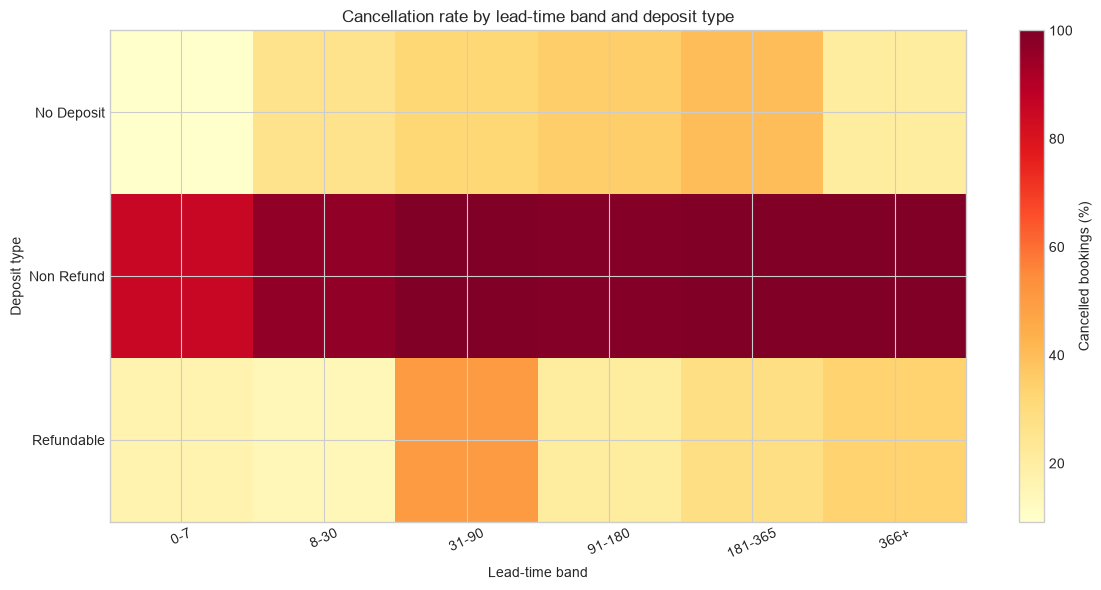

In [195]:
lead_deposit = bookings.groupby(["lead_time_band", "deposit_type"], observed=False)["is_canceled"].agg(bookings="size", cancellation_rate="mean")
lead_deposit["cancellation_rate_pct"] = lead_deposit["cancellation_rate"] * 100
lead_deposit_rates = lead_deposit["cancellation_rate_pct"].unstack()
display(lead_deposit.round(3))
fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(lead_deposit_rates.T, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(len(lead_deposit_rates.index)), lead_deposit_rates.index)
ax.set_yticks(range(len(lead_deposit_rates.columns)), lead_deposit_rates.columns)
ax.set_title("Cancellation rate by lead-time band and deposit type")
ax.set_xlabel("Lead-time band")
ax.set_ylabel("Deposit type")
ax.tick_params(axis="x", rotation=25)
fig.colorbar(im, ax=ax, label="Cancelled bookings (%)")
fig.tight_layout()
plt.show()


## 24. Cancellation rate by customer type and hotel

We compare customer types within each hotel to identify whether cancellation behavior is consistent across properties.


bookings  cancellation_rate  \
customer_type   hotel                                       
Contract        City Hotel        2300              0.480   
                Resort Hotel      1776              0.088   
Group           City Hotel         293              0.099   
                Resort Hotel       284              0.106   
Transient       City Hotel       59404              0.456   
                Resort Hotel     30209              0.312   
Transient-Party City Hotel       17333              0.281   
                Resort Hotel      7791              0.195   

                              cancellation_rate_pct  
customer_type   hotel                                
Contract        City Hotel                   48.043  
                Resort Hotel                  8.840  
Group           City Hotel                    9.898  
                Resort Hotel                 10.563  
Transient       City Hotel                   45.616  
                Resort Hotel                 31.170  
Transient-Party City Hotel                   28.097  
                Resort Hotel                 19.497

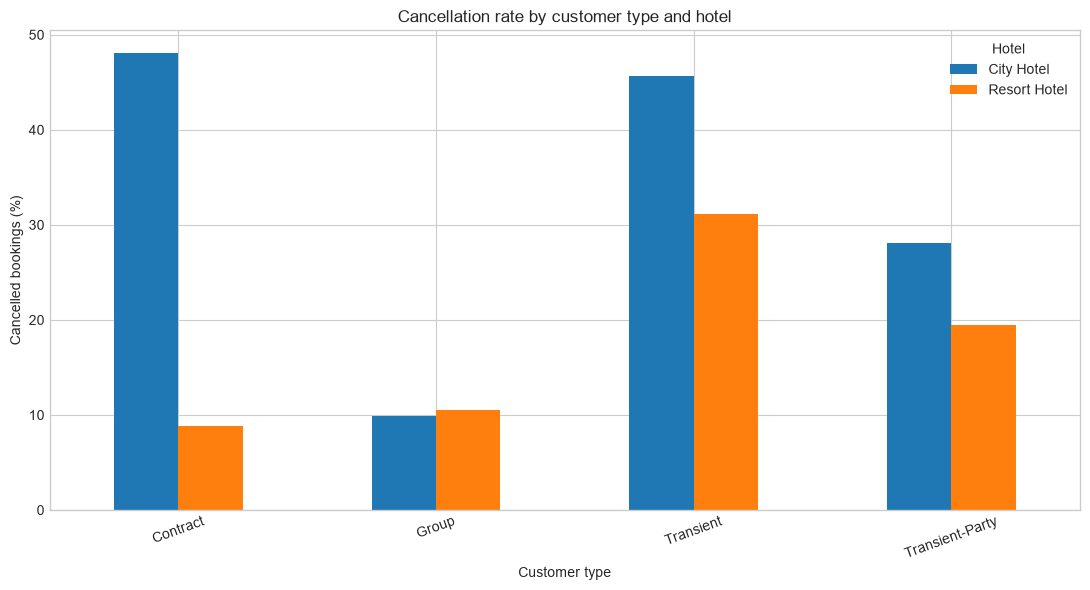

In [196]:
customer_hotel = bookings.groupby(["customer_type", "hotel"])["is_canceled"].agg(bookings="size", cancellation_rate="mean")
customer_hotel["cancellation_rate_pct"] = customer_hotel["cancellation_rate"] * 100
display(customer_hotel.round(3))
fig, ax = plt.subplots(figsize=(11, 6))
customer_hotel["cancellation_rate_pct"].unstack().plot.bar(ax=ax)
ax.set_title("Cancellation rate by customer type and hotel")
ax.set_xlabel("Customer type")
ax.set_ylabel("Cancelled bookings (%)")
ax.tick_params(axis="x", rotation=20)
ax.legend(title="Hotel")
fig.tight_layout()
plt.show()


## 25. Cancellation rate by country with a minimum sample size

We keep countries with at least 100 bookings so that rankings are not driven by tiny groups.


,bookings,cancelled,cancellation_rate,cancellation_rate_pct
country,,,,
PRT,48590,27519,0.566,56.635
AGO,362,205,0.566,56.630
CHN,999,462,0.462,46.246
MAR,259,109,0.421,42.085
KOR,133,55,0.414,41.353
TUR,248,102,0.411,41.129
LUX,287,109,0.380,37.979
RUS,632,239,0.378,37.816
BRA,2224,830,0.373,37.320


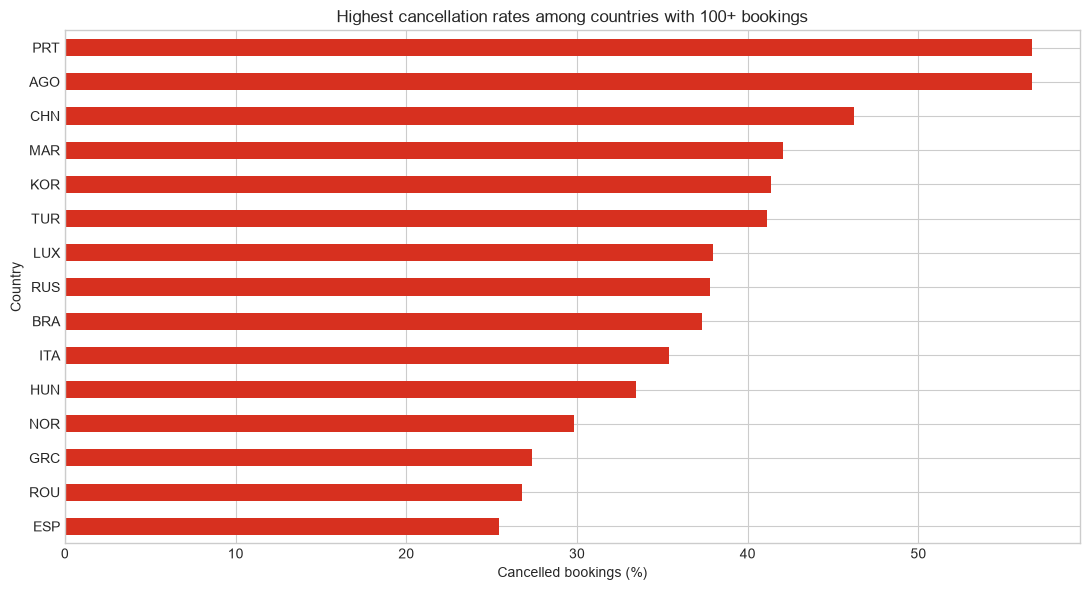

In [197]:
country_cancel = bookings.groupby("country")["is_canceled"].agg(bookings="size", cancelled="sum", cancellation_rate="mean")
country_cancel = country_cancel.loc[country_cancel["bookings"] >= 100].copy()
country_cancel["cancellation_rate_pct"] = country_cancel["cancellation_rate"] * 100
country_cancel = country_cancel.sort_values("cancellation_rate", ascending=False)
display(country_cancel.head(15).round(3))
fig, ax = plt.subplots(figsize=(11, 6))
country_cancel.head(15).sort_values("cancellation_rate_pct")["cancellation_rate_pct"].plot.barh(ax=ax, color="#d7301f")
ax.set_title("Highest cancellation rates among countries with 100+ bookings")
ax.set_xlabel("Cancelled bookings (%)")
ax.set_ylabel("Country")
fig.tight_layout()
plt.show()


## 26. Cancellation rate by distribution channel and market segment

The heatmap compares cancellation rates across two acquisition dimensions; booking counts are displayed first to provide context.


bookings  cancelled  cancellation_rate  \
distribution_channel market_segment                                           
Corporate            Aviation             227         51              0.225   
                     Complementary         89         20              0.225   
                     Corporate           4788        878              0.183   
                     Direct                90         10              0.111   
                     Groups              1228        398              0.324   
                     Offline TA/TO        212        103              0.486   
                     Online TA             43         14              0.326   
Direct               Complementary        576         70              0.122   
                     Corporate            172         19              0.110   
                     Direct             12276       1913              0.156   
                     Groups              1472        543              0.369   
                     Offline TA/TO         16          3              0.188   
                     Online TA            133          9              0.068   
GDS                  Direct                 1          0              0.000   
                     Offline TA/TO         45          8              0.178   
                     Online TA            147         29              0.197   
TA/TO                Aviation              10          1              0.100   
                     Complementary         78          7              0.090   
                     Corporate            335         95              0.284   
                     Direct               237         10              0.042   
                     Groups             17111      11156              0.652   
                     Offline TA/TO      23946       8197              0.342   
                     Online TA          56153      20686              0.368   
Undefined            Direct                 2          1              0.500   
                     Online TA              1          1              1.000   
                     Undefined              2          2              1.000   

                                     cancellation_rate_pct  
distribution_channel market_segment                         
Corporate            Aviation                       22.467  
                     Complementary                  22.472  
                     Corporate                      18.338  
                     Direct                         11.111  
                     Groups                         32.410  
                     Offline TA/TO                  48.585  
                     Online TA                      32.558  
Direct               Complementary                  12.153  
                     Corporate                      11.047  
                     Direct                         15.583  
                     Groups                         36.889  
                     Offline TA/TO                  18.750  
                     Online TA                       6.767  
GDS                  Direct                          0.000  
                     Offline TA/TO                  17.778  
                     Online TA                      19.728  
TA/TO                Aviation                       10.000  
                     Complementary                   8.974  
                     Corporate                      28.358  
                     Direct                          4.219  
                     Groups                         65.198  
                     Offline TA/TO                  34.231  
                     Online TA                      36.839  
Undefined            Direct                         50.000  
                     Online TA                     100.000  
                     Undefined                     100.000

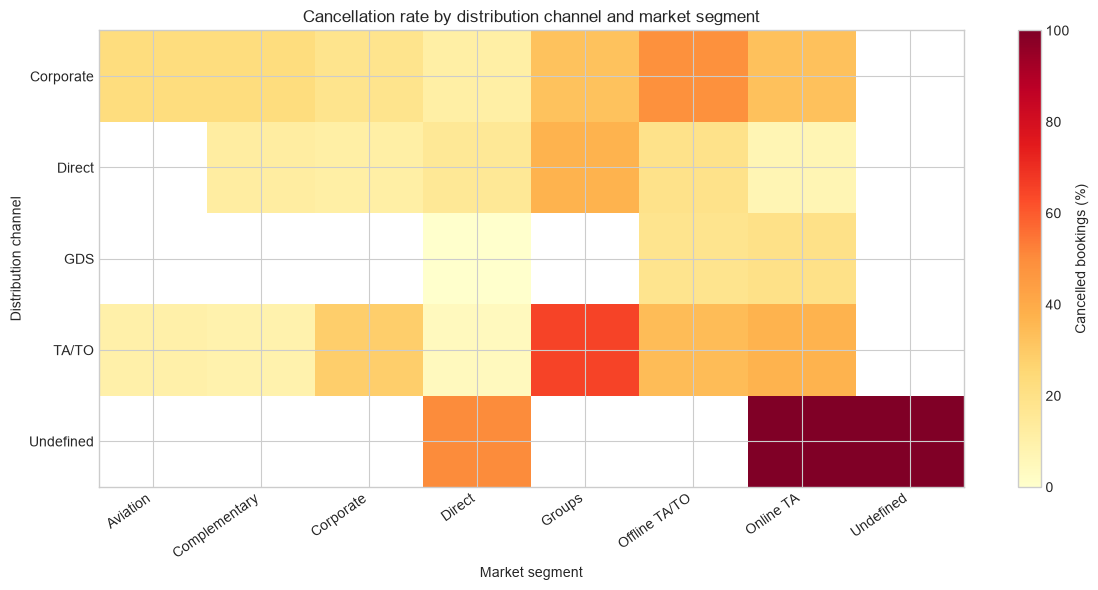

In [198]:
channel_segment = bookings.groupby(["distribution_channel", "market_segment"])["is_canceled"].agg(bookings="size", cancelled="sum", cancellation_rate="mean")
channel_segment["cancellation_rate_pct"] = channel_segment["cancellation_rate"] * 100
channel_segment_rates = channel_segment["cancellation_rate_pct"].unstack()
display(channel_segment.round(3))
fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(channel_segment_rates, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(len(channel_segment_rates.columns)), channel_segment_rates.columns, rotation=35, ha="right")
ax.set_yticks(range(len(channel_segment_rates.index)), channel_segment_rates.index)
ax.set_title("Cancellation rate by distribution channel and market segment")
ax.set_xlabel("Market segment")
ax.set_ylabel("Distribution channel")
fig.colorbar(im, ax=ax, label="Cancelled bookings (%)")
fig.tight_layout()
plt.show()


## 27. Cancelled versus non-cancelled lead-time distributions

We compare the distributions directly instead of relying only on lead-time bands.


,bookings,median,mean
is_canceled,,,
0,75166,45.0,79.984687
1,44224,113.0,144.848815


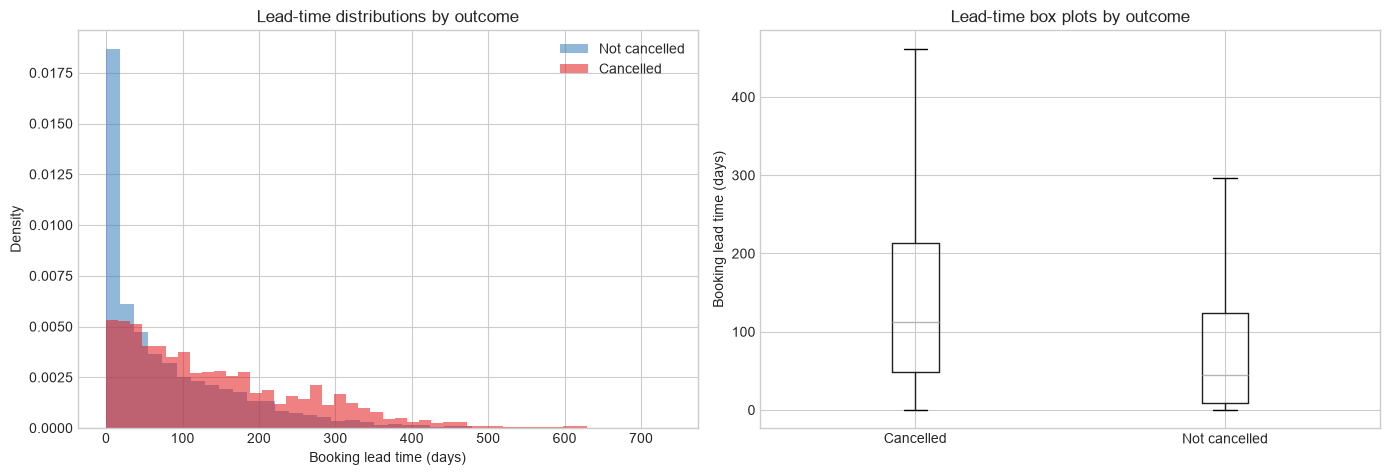

In [199]:
lead_outcome = bookings.groupby("is_canceled")["lead_time"].agg(bookings="size", median="median", mean="mean")
display(lead_outcome)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for outcome, label, color in [(0, "Not cancelled", "#377eb8"), (1, "Cancelled", "#e41a1c")]:
    values = bookings.loc[bookings["is_canceled"] == outcome, "lead_time"]
    axes[0].hist(values, bins=40, alpha=0.55, density=True, label=label, color=color)
lead_plot = bookings.assign(outcome=bookings["is_canceled"].map({0: "Not cancelled", 1: "Cancelled"}))
lead_plot.boxplot(column="lead_time", by="outcome", ax=axes[1], showfliers=False)
axes[0].set_title("Lead-time distributions by outcome")
axes[0].set_xlabel("Booking lead time (days)")
axes[0].set_ylabel("Density")
axes[0].legend()
axes[1].set_title("Lead-time box plots by outcome")
axes[1].set_xlabel("")
axes[1].set_ylabel("Booking lead time (days)")
fig.suptitle("")
fig.tight_layout()
plt.show()


## 28. Cancellation rate by total stay nights

We group total stay length into interpretable bands and show both cancellation rate and booking volume.


,bookings,cancelled,cancellation_rate,cancellation_rate_pct
total_stay_band,,,,
0-1,21735,5306,0.244,24.412
2-3,54719,23514,0.430,42.972
4-5,25167,9021,0.358,35.845
6-7,12512,4504,0.360,35.997
8-14,4818,1636,0.340,33.956
15+,439,243,0.554,55.353


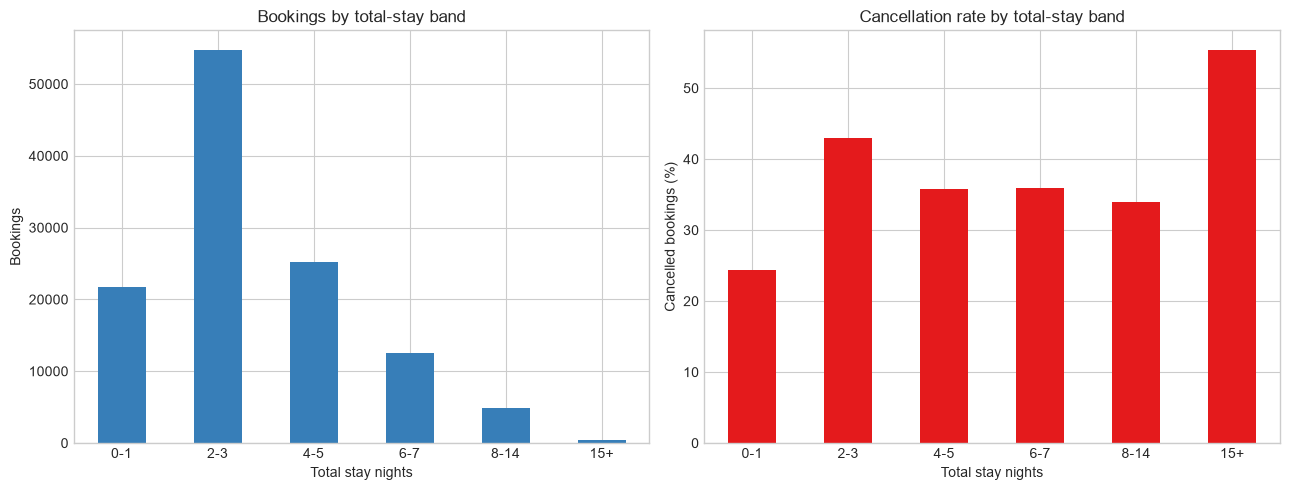

In [200]:
stay_bins = [-1, 1, 3, 5, 7, 14, float("inf")]
stay_labels = ["0-1", "2-3", "4-5", "6-7", "8-14", "15+"]
stay_cancel = bookings.assign(total_stay_band=pd.cut(bookings["nights"], bins=stay_bins, labels=stay_labels)).groupby("total_stay_band", observed=False)["is_canceled"].agg(bookings="size", cancelled="sum", cancellation_rate="mean")
stay_cancel["cancellation_rate_pct"] = stay_cancel["cancellation_rate"] * 100
display(stay_cancel.round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
stay_cancel["bookings"].plot.bar(ax=axes[0], color="#377eb8")
stay_cancel["cancellation_rate_pct"].plot.bar(ax=axes[1], color="#e41a1c")
axes[0].set_title("Bookings by total-stay band")
axes[0].set_ylabel("Bookings")
axes[1].set_title("Cancellation rate by total-stay band")
axes[1].set_ylabel("Cancelled bookings (%)")
for ax in axes:
    ax.set_xlabel("Total stay nights")
    ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()


## 29. Cancellation rate by arrival month and room type

We examine room-type seasonality while excluding room types with fewer than 100 bookings overall.


bookings  cancellation_rate  \
arrival_month reserved_room_type                                
1             A                       4644              0.316   
              B                         80              0.350   
              C                         16              0.000   
              D                        657              0.304   
              E                        291              0.189   
...                                    ...                ...   
12            D                        988              0.319   
              E                        385              0.268   
              F                        180              0.289   
              G                        102              0.255   
              H                         42              0.357   

                                  cancellation_rate_pct  
arrival_month reserved_room_type                         
1             A                                  31.589  
              B                                  35.000  
              C                                   0.000  
              D                                  30.441  
              E                                  18.900  
...                                                 ...  
12            D                                  31.883  
              E                                  26.753  
              F                                  28.889  
              G                                  25.490  
              H                                  35.714  

[96 rows x 3 columns]

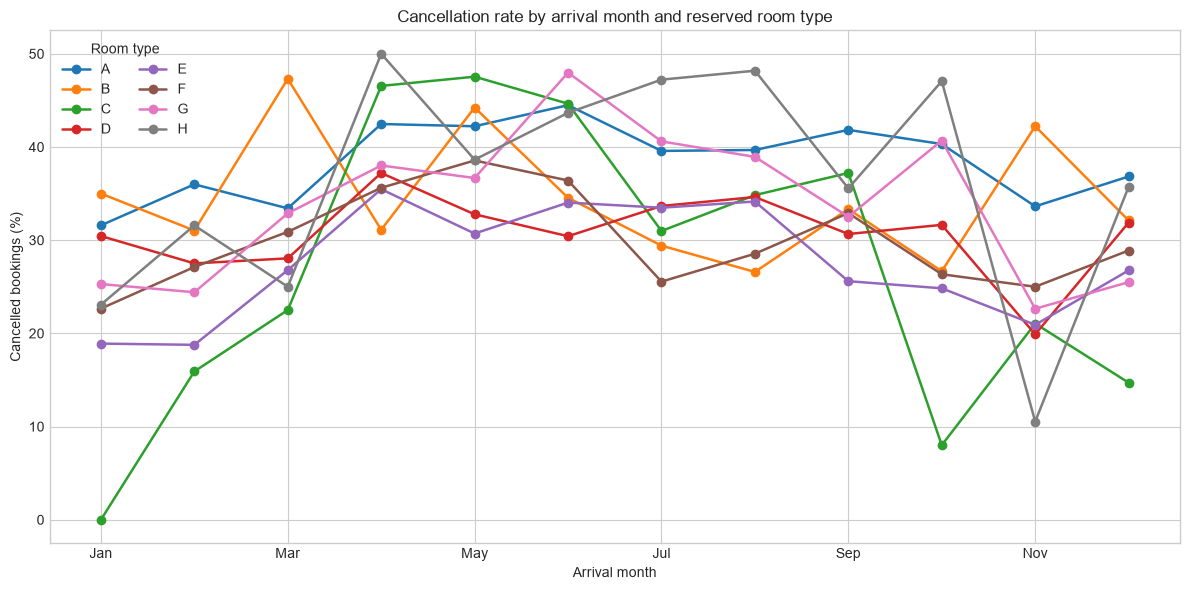

In [201]:
room_counts = bookings["reserved_room_type"].value_counts()
room_keep = room_counts[room_counts >= 100].index
month_room = bookings.loc[bookings["reserved_room_type"].isin(room_keep)].groupby(["arrival_month", "reserved_room_type"])["is_canceled"].agg(bookings="size", cancellation_rate="mean")
month_room["cancellation_rate_pct"] = month_room["cancellation_rate"] * 100
month_room_rates = month_room["cancellation_rate_pct"].unstack()
month_room_rates.index = [pd.Timestamp(year=2000, month=int(m), day=1).strftime("%b") for m in month_room_rates.index]
display(month_room.round(3))
fig, ax = plt.subplots(figsize=(12, 6))
month_room_rates.plot(ax=ax, marker="o", linewidth=1.8)
ax.set_title("Cancellation rate by arrival month and reserved room type")
ax.set_xlabel("Arrival month")
ax.set_ylabel("Cancelled bookings (%)")
ax.legend(title="Room type", ncol=2)
fig.tight_layout()
plt.show()


## 30. Which groups contribute the most cancellations?

Cancellation rate identifies risk, while cancelled count identifies where the largest absolute cancellation volume comes from.


,bookings,cancelled,cancellation_rate,cancellation_rate_pct,share_of_all_cancellations_pct
market_segment,,,,,
Online TA,56477,20739,0.367,36.721,46.895
Groups,19811,12097,0.611,61.062,27.354
Offline TA/TO,24219,8311,0.343,34.316,18.793
Direct,12606,1934,0.153,15.342,4.373
Corporate,5295,992,0.187,18.735,2.243
Complementary,743,97,0.131,13.055,0.219
Aviation,237,52,0.219,21.941,0.118
Undefined,2,2,1.000,100.000,0.005


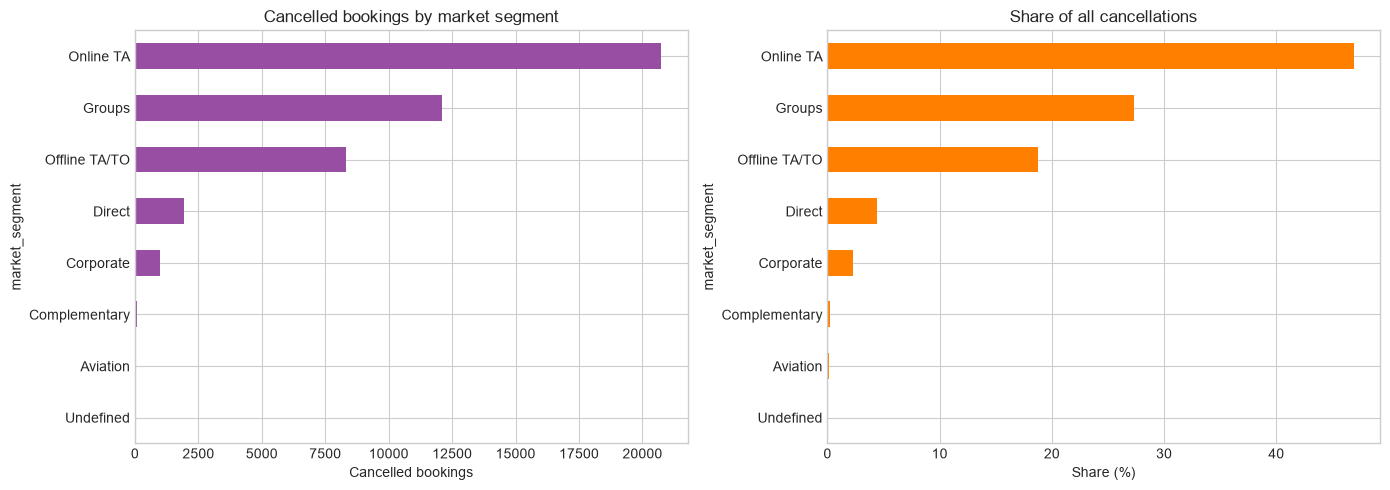

In [202]:
segment_contribution = bookings.groupby("market_segment")["is_canceled"].agg(bookings="size", cancelled="sum", cancellation_rate="mean")
segment_contribution["cancellation_rate_pct"] = segment_contribution["cancellation_rate"] * 100
segment_contribution["share_of_all_cancellations_pct"] = segment_contribution["cancelled"] / bookings["is_canceled"].sum() * 100
segment_contribution = segment_contribution.sort_values("cancelled", ascending=False)
display(segment_contribution.round(3))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
segment_contribution["cancelled"].sort_values().plot.barh(ax=axes[0], color="#984ea3")
segment_contribution["share_of_all_cancellations_pct"].sort_values().plot.barh(ax=axes[1], color="#ff7f00")
axes[0].set_title("Cancelled bookings by market segment")
axes[0].set_xlabel("Cancelled bookings")
axes[1].set_title("Share of all cancellations")
axes[1].set_xlabel("Share (%)")
fig.tight_layout()
plt.show()


## 31. Cancellation risk matrix for overselling decisions

This business-oriented matrix combines hotel, lead time, and deposit type. It reports booking count, cancellation rate, and cancelled booking count together.


bookings  cancelled  \
hotel        lead_time_band deposit_type                        
City Hotel   91-180         Refundable           6          6   
             181-365        Refundable           3          3   
             366+           Non Refund        1748       1748   
             181-365        Non Refund        4934       4930   
             91-180         Non Refund        3449       3443   
             31-90          Non Refund        2197       2192   
             8-30           Non Refund         460        458   
             0-7            Non Refund          80         73   
             8-30           Refundable           3          2   
             0-7            Refundable           2          1   
             181-365        No Deposit        9307       4001   
             91-180         No Deposit       14768       5297   
             31-90          Refundable           6          2   
                            No Deposit       18594       6106   
             8-30           No Deposit       12091       3420   
             366+           No Deposit         956        175   
             0-7            No Deposit       10726       1245   
             366+           Refundable           0          0   
Resort Hotel 31-90          Non Refund         209        209   
                            Refundable           2          2   
             366+           Non Refund         117        117   
             181-365        Non Refund         680        676   
             91-180         Non Refund         638        599   
             0-7            Non Refund          41         30   
             8-30           Non Refund          34         19   
             181-365        No Deposit        6598       2333   
             366+           Refundable           3          1   
             91-180         No Deposit        7492       2463   
             31-90          No Deposit        8545       2630   
             366+           No Deposit         324         89   

                                          cancellation_rate  \
hotel        lead_time_band deposit_type                      
City Hotel   91-180         Refundable                1.000   
             181-365        Refundable                1.000   
             366+           Non Refund                1.000   
             181-365        Non Refund                0.999   
             91-180         Non Refund                0.998   
             31-90          Non Refund                0.998   
             8-30           Non Refund                0.996   
             0-7            Non Refund                0.912   
             8-30           Refundable                0.667   
             0-7            Refundable                0.500   
             181-365        No Deposit                0.430   
             91-180         No Deposit                0.359   
             31-90          Refundable                0.333   
                            No Deposit                0.328   
             8-30           No Deposit                0.283   
             366+           No Deposit                0.183   
             0-7            No Deposit                0.116   
             366+           Refundable                  NaN   
Resort Hotel 31-90          Non Refund                1.000   
                            Refundable                1.000   
             366+           Non Refund                1.000   
             181-365        Non Refund                0.994   
             91-180         Non Refund                0.939   
             0-7            Non Refund                0.732   
             8-30           Non Refund                0.559   
             181-365        No Deposit                0.354   
             366+           Refundable                0.333   
             91-180         No Deposit                0.329   
             31-90          No Deposit                0.308   
        

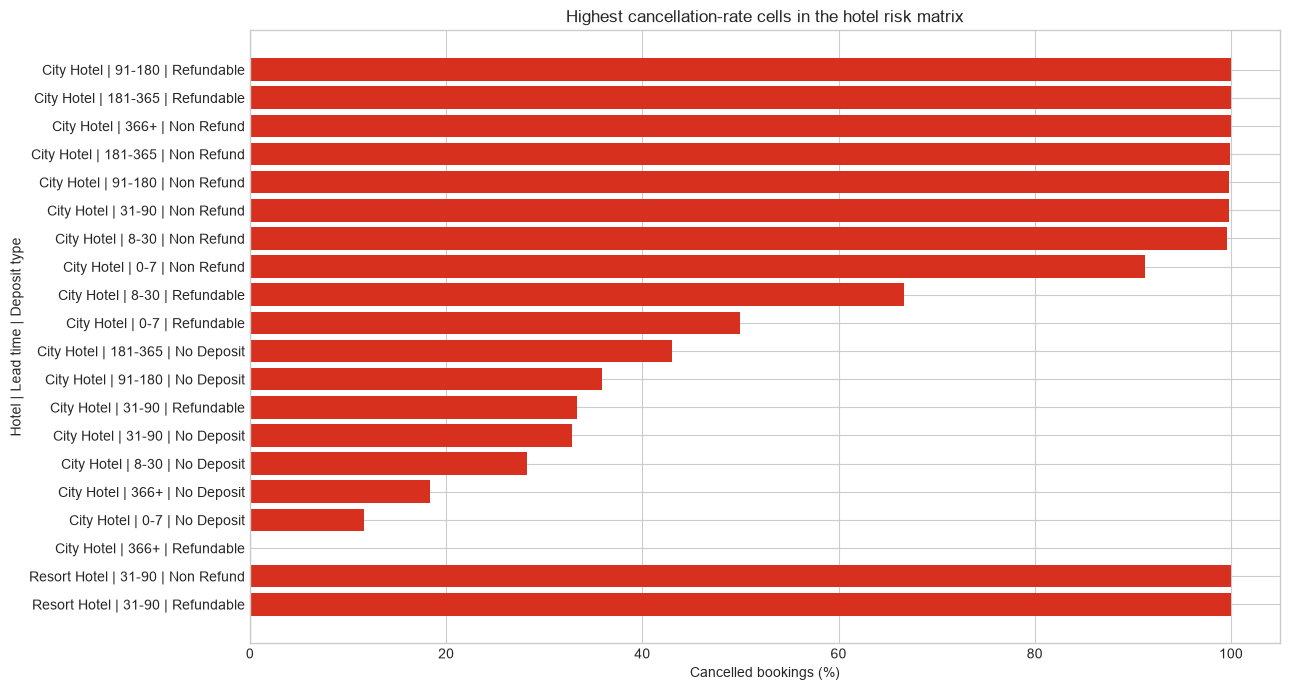

In [203]:
risk_matrix = bookings.groupby(["hotel", "lead_time_band", "deposit_type"], observed=False)["is_canceled"].agg(bookings="size", cancelled="sum", cancellation_rate="mean")
risk_matrix["cancellation_rate_pct"] = risk_matrix["cancellation_rate"] * 100
risk_matrix = risk_matrix.sort_values(["hotel", "cancellation_rate"], ascending=[True, False])
display(risk_matrix.head(30).round(3))
plot_risk = risk_matrix.reset_index().head(20)
fig, ax = plt.subplots(figsize=(13, 7))
labels = plot_risk["hotel"] + " | " + plot_risk["lead_time_band"].astype(str) + " | " + plot_risk["deposit_type"]
ax.barh(labels.iloc[::-1], plot_risk["cancellation_rate_pct"].iloc[::-1], color="#d7301f")
ax.set_title("Highest cancellation-rate cells in the hotel risk matrix")
ax.set_xlabel("Cancelled bookings (%)")
ax.set_ylabel("Hotel | Lead time | Deposit type")
fig.tight_layout()
plt.show()


## 32. Does booking party size relate to cancellation?

We group bookings by the number of adults, children, and babies. The table keeps booking volume beside cancellation rate so small party-size groups are not over-interpreted.


In [204]:
party_size_data = bookings.assign(
    total_guests=bookings["adults"] + bookings["children"] + bookings["babies"]
)
party_size_data["party_size_band"] = pd.cut(
    party_size_data["total_guests"],
    bins=[-1, 1, 2, 4, 6, float("inf")],
    labels=["0-1", "2", "3-4", "5-6", "7+"]
)
party_size_summary = party_size_data.groupby("party_size_band", observed=False)["is_canceled"].agg(bookings="size", cancelled="sum", cancellation_rate="mean")
party_size_summary["cancellation_rate_pct"] = party_size_summary["cancellation_rate"] * 100
display(party_size_summary.round(3))


,bookings,cancelled,cancellation_rate,cancellation_rate_pct
party_size_band,,,,
0-1,22761,6580,0.289,28.909
2,82048,32569,0.397,39.695
3-4,14423,5022,0.348,34.819
5-6,138,35,0.254,25.362
7+,16,14,0.875,87.500


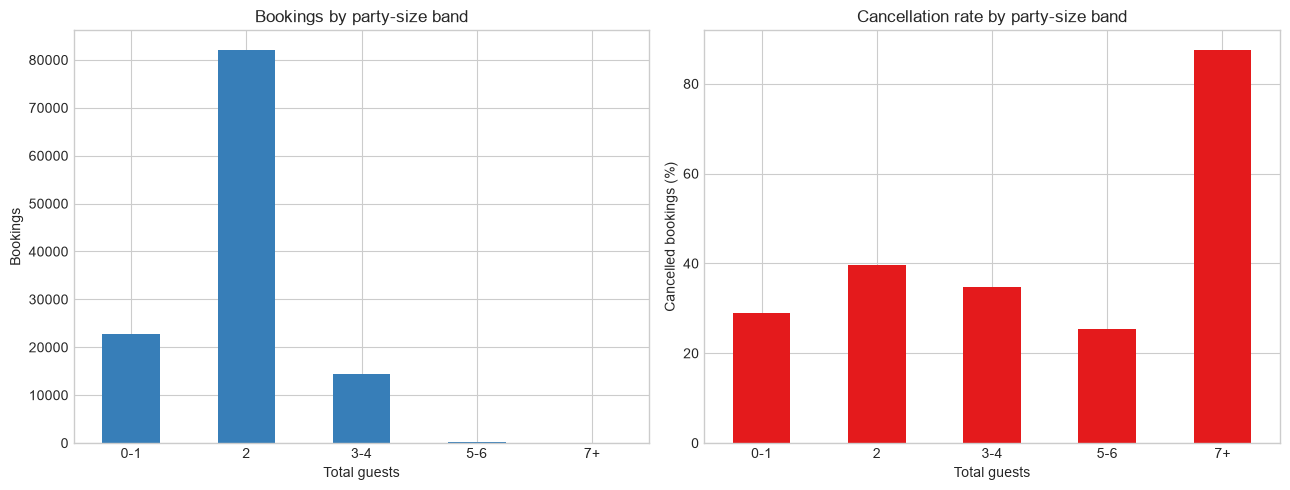

In [205]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
party_size_summary["bookings"].plot.bar(ax=axes[0], color="#377eb8")
party_size_summary["cancellation_rate_pct"].plot.bar(ax=axes[1], color="#e41a1c")
axes[0].set_title("Bookings by party-size band")
axes[0].set_ylabel("Bookings")
axes[1].set_title("Cancellation rate by party-size band")
axes[1].set_ylabel("Cancelled bookings (%)")
for ax in axes:
    ax.set_xlabel("Total guests")
    ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()


## 33. Does meal plan relate to cancellation?

Meal plan is a reservation preference that may differ between leisure and business stays. We compare cancellation rate and volume for each meal category.


In [206]:
meal_summary = bookings.groupby("meal")["is_canceled"].agg(bookings="size", cancelled="sum", cancellation_rate="mean")
meal_summary["cancellation_rate_pct"] = meal_summary["cancellation_rate"] * 100
meal_summary = meal_summary.sort_values("bookings", ascending=False)
display(meal_summary.round(3))


,bookings,cancelled,cancellation_rate,cancellation_rate_pct
meal,,,,
BB,92310,34510,0.374,37.385
HB,14463,4984,0.345,34.460
SC,10650,3966,0.372,37.239
Undefined,1169,286,0.245,24.465
FB,798,478,0.599,59.900


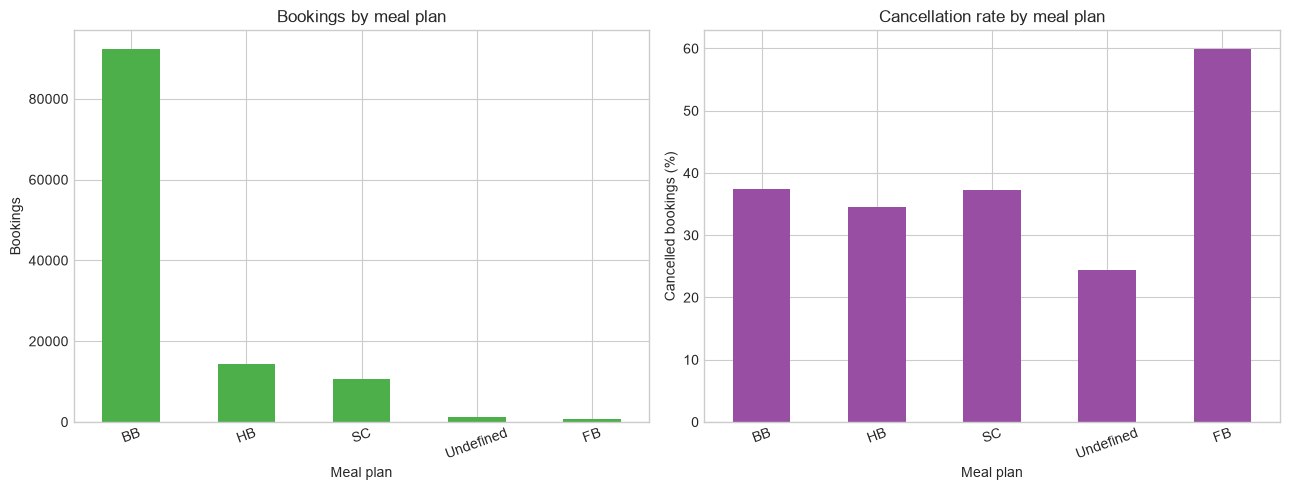

In [207]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
meal_summary["bookings"].plot.bar(ax=axes[0], color="#4daf4a")
meal_summary["cancellation_rate_pct"].plot.bar(ax=axes[1], color="#984ea3")
axes[0].set_title("Bookings by meal plan")
axes[0].set_ylabel("Bookings")
axes[1].set_title("Cancellation rate by meal plan")
axes[1].set_ylabel("Cancelled bookings (%)")
for ax in axes:
    ax.set_xlabel("Meal plan")
    ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
plt.show()


## 34. How does previous booking history relate to cancellation?

We examine previous completed bookings and previous cancellations separately. These are historical fields available before the current booking outcome.


In [208]:
history_data = bookings.copy()
history_data["previous_completed_band"] = pd.cut(
    history_data["previous_bookings_not_canceled"],
    bins=[-1, 0, 1, 3, float("inf")],
    labels=["0", "1", "2-3", "4+"]
)
history_summary = history_data.groupby("previous_completed_band", observed=False)["is_canceled"].agg(bookings="size", cancelled="sum", cancellation_rate="mean")
history_summary["cancellation_rate_pct"] = history_summary["cancellation_rate"] * 100
display(history_summary.round(3))


,bookings,cancelled,cancellation_rate,cancellation_rate_pct
previous_completed_band,,,,
0,115770,44024,0.380,38.027
1,1542,79,0.051,5.123
2-3,913,49,0.054,5.367
4+,1165,72,0.062,6.180


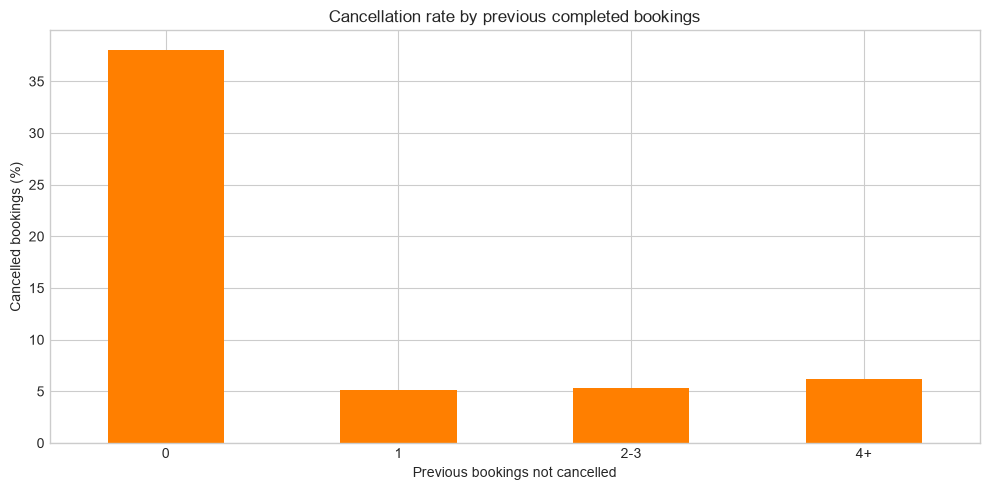

In [209]:
fig, ax = plt.subplots(figsize=(10, 5))
history_summary["cancellation_rate_pct"].plot.bar(ax=ax, color="#ff7f00")
ax.set_title("Cancellation rate by previous completed bookings")
ax.set_xlabel("Previous bookings not cancelled")
ax.set_ylabel("Cancelled bookings (%)")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()


## 35. Do agent and company bookings have different cancellation rates?

We compare bookings with and without an agent or company identifier. Missing identifiers are treated as a separate operational category, not as a country or organization.


In [210]:
partner_data = bookings.assign(
    agent_group=bookings["agent"].notna().map({True: "Agent present", False: "No agent"}),
    company_group=bookings["company"].notna().map({True: "Company present", False: "No company"})
)
agent_summary = partner_data.groupby("agent_group")["is_canceled"].agg(bookings="size", cancelled="sum", cancellation_rate="mean")
company_summary = partner_data.groupby("company_group")["is_canceled"].agg(bookings="size", cancelled="sum", cancellation_rate="mean")
agent_summary["cancellation_rate_pct"] = agent_summary["cancellation_rate"] * 100
company_summary["cancellation_rate_pct"] = company_summary["cancellation_rate"] * 100
display(agent_summary.round(3))
display(company_summary.round(3))


,bookings,cancelled,cancellation_rate,cancellation_rate_pct
agent_group,,,,
Agent present,103050,40194,0.390,39.004
No agent,16340,4030,0.247,24.663


,bookings,cancelled,cancellation_rate,cancellation_rate_pct
company_group,,,,
Company present,6797,1191,0.175,17.522
No company,112593,43033,0.382,38.220


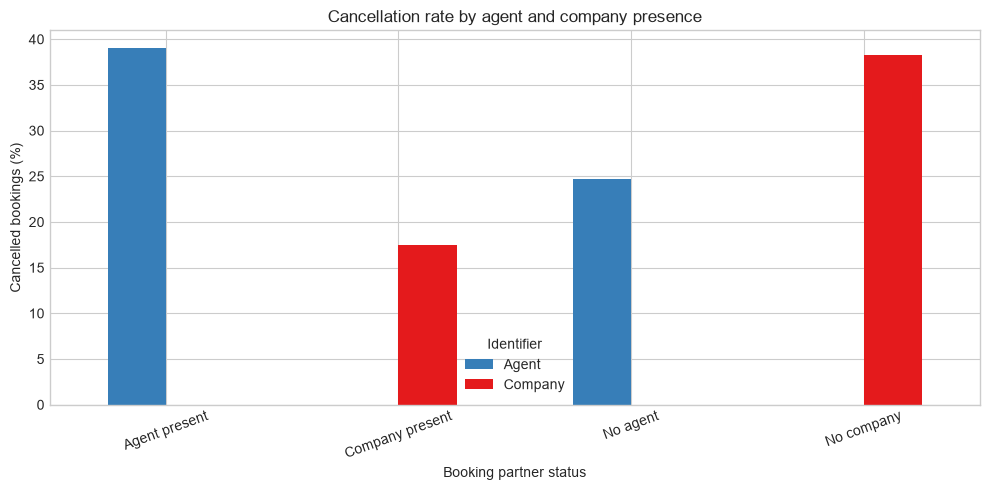

In [211]:
partner_rates = pd.DataFrame({"Agent": agent_summary["cancellation_rate_pct"], "Company": company_summary["cancellation_rate_pct"]})
fig, ax = plt.subplots(figsize=(10, 5))
partner_rates.plot.bar(ax=ax, color=["#377eb8", "#e41a1c"])
ax.set_title("Cancellation rate by agent and company presence")
ax.set_xlabel("Booking partner status")
ax.set_ylabel("Cancelled bookings (%)")
ax.tick_params(axis="x", rotation=20)
ax.legend(title="Identifier")
fig.tight_layout()
plt.show()


## 36. Does the arrival day of the month relate to cancellation?

We group arrival days into four calendar bands. This avoids over-interpreting individual days while showing whether cancellation behavior changes through the month.


In [212]:
day_data = bookings.assign(
    arrival_day_band=pd.cut(
        bookings["arrival_date_day_of_month"],
        bins=[0, 7, 14, 21, 31],
        labels=["1-7", "8-14", "15-21", "22-31"]
    )
)
day_summary = day_data.groupby("arrival_day_band", observed=False)["is_canceled"].agg(bookings="size", cancelled="sum", cancellation_rate="mean")
day_summary["cancellation_rate_pct"] = day_summary["cancellation_rate"] * 100
display(day_summary.round(3))


,bookings,cancelled,cancellation_rate,cancellation_rate_pct
arrival_day_band,,,,
1-7,27114,10122,0.373,37.331
8-14,26842,9892,0.369,36.853
15-21,28533,10677,0.374,37.420
22-31,36901,13533,0.367,36.674


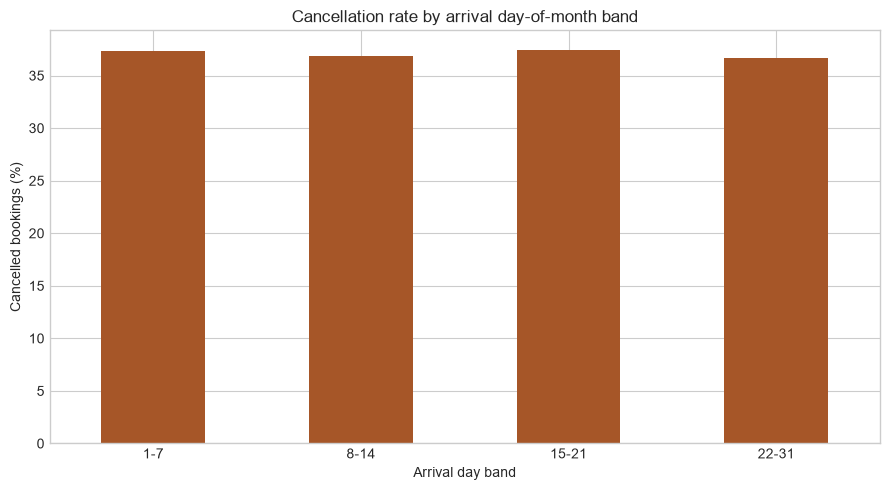

In [213]:
fig, ax = plt.subplots(figsize=(9, 5))
day_summary["cancellation_rate_pct"].plot.bar(ax=ax, color="#a65628")
ax.set_title("Cancellation rate by arrival day-of-month band")
ax.set_xlabel("Arrival day band")
ax.set_ylabel("Cancelled bookings (%)")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()


## 37. Does distribution-channel risk differ by hotel?

This interaction view checks whether the same distribution channel behaves differently at City Hotel and Resort Hotel.


bookings  cancelled  cancellation_rate  \
distribution_channel hotel                                                  
Corporate            City Hotel        3408        786              0.231   
                     Resort Hotel      3269        688              0.210   
Direct               City Hotel        6780       1232              0.182   
                     Resort Hotel      7865       1325              0.168   
GDS                  City Hotel         193         37              0.192   
TA/TO                City Hotel       68945      31043              0.450   
                     Resort Hotel     28925       9109              0.315   
Undefined            City Hotel           4          4              1.000   
                     Resort Hotel         1          0              0.000   

                                   cancellation_rate_pct  
distribution_channel hotel                                
Corporate            City Hotel                   23.063  
                     Resort Hotel                 21.046  
Direct               City Hotel                   18.171  
                     Resort Hotel                 16.847  
GDS                  City Hotel                   19.171  
TA/TO                City Hotel                   45.026  
                     Resort Hotel                 31.492  
Undefined            City Hotel                  100.000  
                     Resort Hotel                  0.000

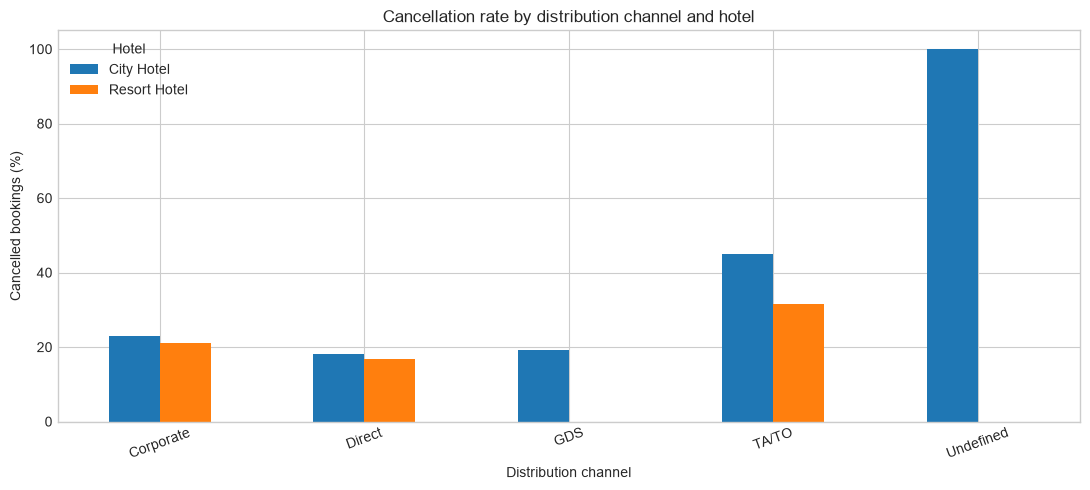

In [214]:
channel_hotel = bookings.groupby(["distribution_channel", "hotel"])["is_canceled"].agg(bookings="size", cancelled="sum", cancellation_rate="mean")
channel_hotel["cancellation_rate_pct"] = channel_hotel["cancellation_rate"] * 100
display(channel_hotel.round(3))
fig, ax = plt.subplots(figsize=(11, 5))
channel_hotel["cancellation_rate_pct"].unstack().plot.bar(ax=ax)
ax.set_title("Cancellation rate by distribution channel and hotel")
ax.set_xlabel("Distribution channel")
ax.set_ylabel("Cancelled bookings (%)")
ax.tick_params(axis="x", rotation=20)
ax.legend(title="Hotel")
fig.tight_layout()
plt.show()


## 38. Do special requests have the same meaning at both hotels?

We compare special-request cancellation patterns separately by hotel, retaining counts beside rates.


bookings  cancelled  \
total_of_special_requests hotel                               
0                         City Hotel       47957      26340   
                          Resort Hotel     22361       7216   
1                         City Hotel       21420       4721   
                          Resort Hotel     11806       2597   
2                         City Hotel        8142       1739   
                          Resort Hotel      4827       1127   
3                         City Hotel        1587        280   
                          Resort Hotel       910        166   
4                         City Hotel         198         21   
                          Resort Hotel       142         15   
5                         City Hotel          26          1   
                          Resort Hotel        14          1   

                                        cancellation_rate  \
total_of_special_requests hotel                             
0                         City Hotel                0.549   
                          Resort Hotel              0.323   
1                         City Hotel                0.220   
                          Resort Hotel              0.220   
2                         City Hotel                0.214   
                          Resort Hotel              0.233   
3                         City Hotel                0.176   
                          Resort Hotel              0.182   
4                         City Hotel                0.106   
                          Resort Hotel              0.106   
5                         City Hotel                0.038   
                          Resort Hotel              0.071   

                                        cancellation_rate_pct  
total_of_special_requests hotel                                
0                         City Hotel                   54.924  
                          Resort Hotel                 32.270  
1                         City Hotel                   22.040  
                          Resort Hotel                 21.997  
2                         City Hotel                   21.358  
                          Resort Hotel                 23.348  
3                         City Hotel                   17.643  
                          Resort Hotel                 18.242  
4                         City Hotel                   10.606  
                          Resort Hotel                 10.563  
5                         City Hotel                    3.846  
                          Resort Hotel                  7.143

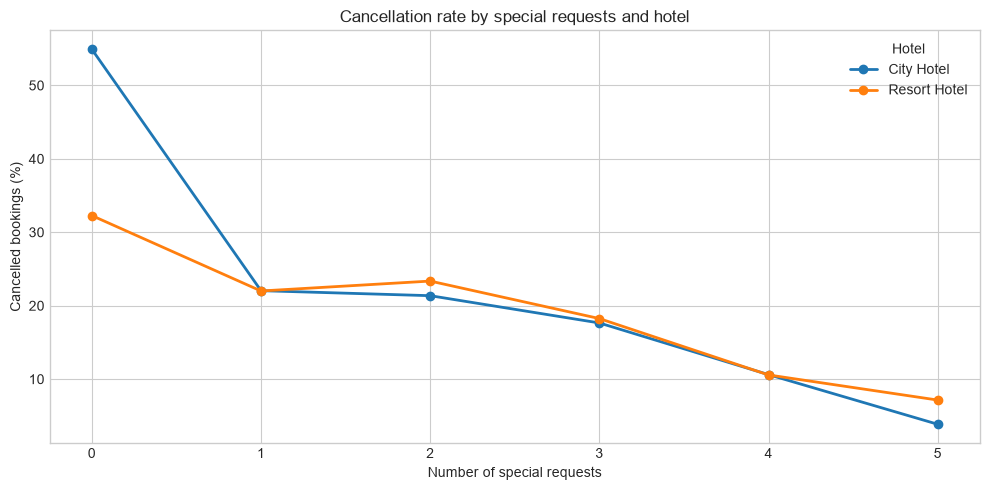

In [215]:
special_hotel = bookings.groupby(["total_of_special_requests", "hotel"])["is_canceled"].agg(bookings="size", cancelled="sum", cancellation_rate="mean")
special_hotel["cancellation_rate_pct"] = special_hotel["cancellation_rate"] * 100
display(special_hotel.round(3))
fig, ax = plt.subplots(figsize=(10, 5))
special_hotel["cancellation_rate_pct"].unstack().plot(ax=ax, marker="o", linewidth=2)
ax.set_title("Cancellation rate by special requests and hotel")
ax.set_xlabel("Number of special requests")
ax.set_ylabel("Cancelled bookings (%)")
ax.legend(title="Hotel")
fig.tight_layout()
plt.show()


## 39. Does repeat-guest status behave differently by hotel?

We check whether the relationship between repeat-guest status and cancellation is consistent across the two hotels.


bookings  cancelled  cancellation_rate  \
guest_group  hotel                                                  
New guest    City Hotel       77298      32661              0.423   
             Resort Hotel     38282      11011              0.288   
Repeat guest City Hotel        2032        441              0.217   
             Resort Hotel      1778        111              0.062   

                           cancellation_rate_pct  
guest_group  hotel                                
New guest    City Hotel                   42.253  
             Resort Hotel                 28.763  
Repeat guest City Hotel                   21.703  
             Resort Hotel                  6.243

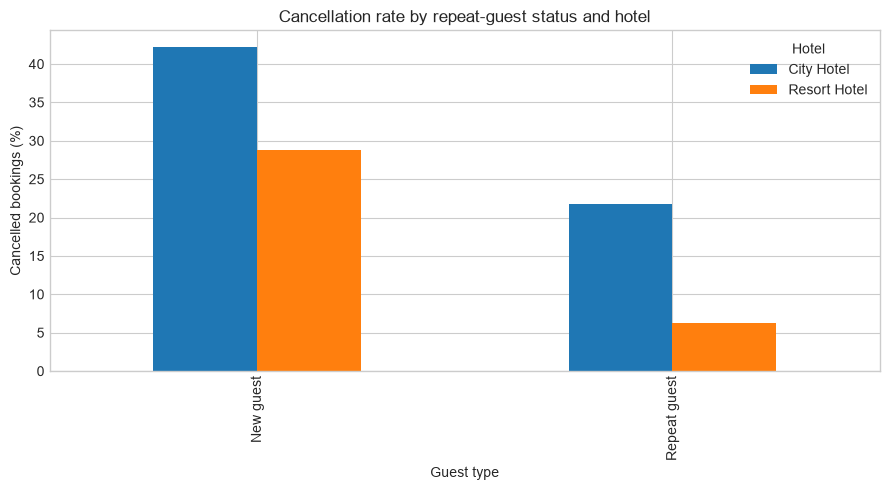

In [216]:
repeat_hotel = bookings.assign(guest_group=bookings["is_repeated_guest"].map({0: "New guest", 1: "Repeat guest"})).groupby(["guest_group", "hotel"])["is_canceled"].agg(bookings="size", cancelled="sum", cancellation_rate="mean")
repeat_hotel["cancellation_rate_pct"] = repeat_hotel["cancellation_rate"] * 100
display(repeat_hotel.round(3))
fig, ax = plt.subplots(figsize=(9, 5))
repeat_hotel["cancellation_rate_pct"].unstack().plot.bar(ax=ax)
ax.set_title("Cancellation rate by repeat-guest status and hotel")
ax.set_xlabel("Guest type")
ax.set_ylabel("Cancelled bookings (%)")
ax.legend(title="Hotel")
fig.tight_layout()
plt.show()


## 40. Do booking changes behave differently by hotel?

This interaction view compares cancellation rates for change-count bands within each hotel.


bookings  cancelled  cancellation_rate  \
change_band hotel                                                  
0           City Hotel       69062      31423              0.455   
            Resort Hotel     32252       9968              0.309   
1           City Hotel        7232        994              0.137   
            Resort Hotel      5469        813              0.149   
2           City Hotel        2244        531              0.237   
            Resort Hotel      1561        235              0.151   
3+          City Hotel         792        154              0.194   
            Resort Hotel       778        106              0.136   

                          cancellation_rate_pct  
change_band hotel                                
0           City Hotel                   45.500  
            Resort Hotel                 30.907  
1           City Hotel                   13.744  
            Resort Hotel                 14.866  
2           City Hotel                   23.663  
            Resort Hotel                 15.054  
3+          City Hotel                   19.444  
            Resort Hotel                 13.625

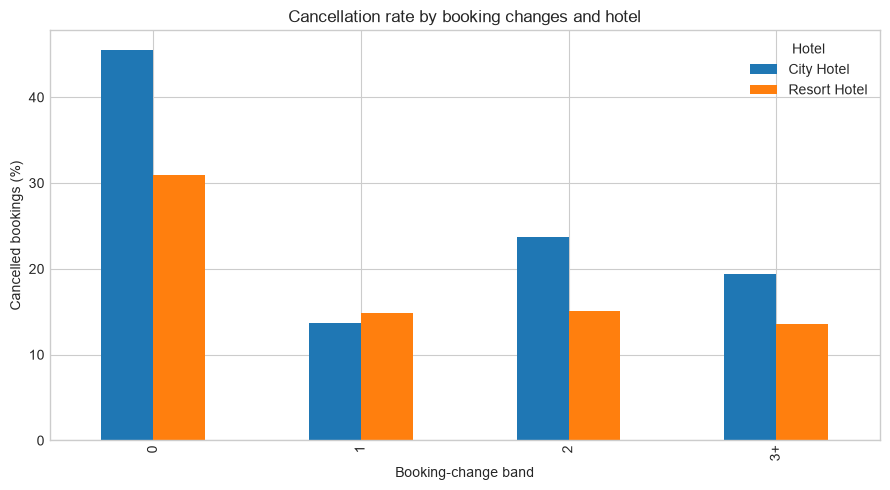

In [217]:
changes_hotel = bookings.assign(change_band=pd.cut(bookings["booking_changes"], bins=[-1, 0, 1, 2, float("inf")], labels=["0", "1", "2", "3+"])).groupby(["change_band", "hotel"], observed=False)["is_canceled"].agg(bookings="size", cancelled="sum", cancellation_rate="mean")
changes_hotel["cancellation_rate_pct"] = changes_hotel["cancellation_rate"] * 100
display(changes_hotel.round(3))
fig, ax = plt.subplots(figsize=(9, 5))
changes_hotel["cancellation_rate_pct"].unstack().plot.bar(ax=ax)
ax.set_title("Cancellation rate by booking changes and hotel")
ax.set_xlabel("Booking-change band")
ax.set_ylabel("Cancelled bookings (%)")
ax.legend(title="Hotel")
fig.tight_layout()
plt.show()


## 41. Which groups combine high cancellation risk and high volume?

A high cancellation rate is not necessarily the largest business problem if the group is small. This scatter plot compares volume, rate, and absolute cancellations.


,bookings,cancelled,cancellation_rate,cancellation_rate_pct
market_segment,,,,
Online TA,56477,20739,0.367,36.721
Groups,19811,12097,0.611,61.062
Offline TA/TO,24219,8311,0.343,34.316
Direct,12606,1934,0.153,15.342
Corporate,5295,992,0.187,18.735
Complementary,743,97,0.131,13.055
Aviation,237,52,0.219,21.941
Undefined,2,2,1.000,100.000


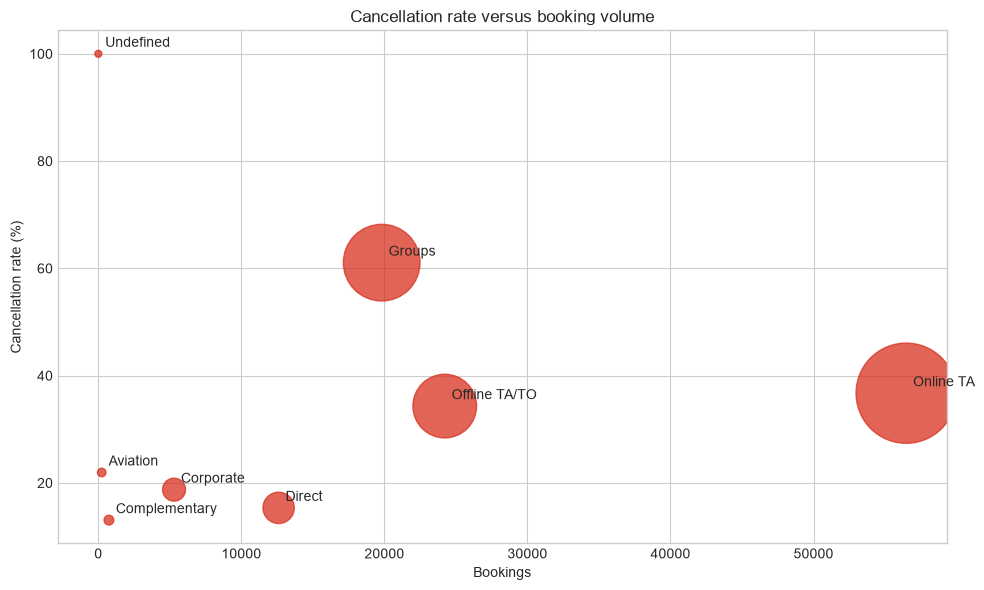

In [218]:
volume_rate = bookings.groupby("market_segment")["is_canceled"].agg(bookings="size", cancelled="sum", cancellation_rate="mean")
volume_rate["cancellation_rate_pct"] = volume_rate["cancellation_rate"] * 100
display(volume_rate.sort_values("cancelled", ascending=False).round(3))
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(volume_rate["bookings"], volume_rate["cancellation_rate_pct"], s=volume_rate["cancelled"] * 0.25 + 25, alpha=0.75, color="#d7301f")
for label, row in volume_rate.iterrows():
    ax.annotate(label, (row["bookings"], row["cancellation_rate_pct"]), xytext=(5, 5), textcoords="offset points")
ax.set_title("Cancellation rate versus booking volume")
ax.set_xlabel("Bookings")
ax.set_ylabel("Cancellation rate (%)")
fig.tight_layout()
plt.show()


## 42. How many cancellations occur each month?

Cancellation rate shows risk, while cancellation volume shows the number of cancelled bookings the hotel actually needs to absorb.


bookings  cancelled  cancellation_rate  \
hotel      arrival_date                                           
City Hotel 2015-07-01        1398        939              21.46   
           2015-08-01        2480       1232              12.78   
           2015-09-01        3529       1543              11.58   
           2015-10-01        3386       1321              10.65   
           2015-11-01        1235        301               6.70   
           2015-12-01        1654        668               8.22   
           2016-01-01        1364        438               7.77   
           2016-02-01        2371        930               9.37   
           2016-03-01        3046       1108              10.14   
           2016-04-01        3561       1539              12.39   
           2016-05-01        3676       1436              11.27   
           2016-06-01        3923       1720              12.53   

                         cancellation_rate_pct  
hotel      arrival_date                         
City Hotel 2015-07-01                  2146.08  
           2015-08-01                  1277.76  
           2015-09-01                  1157.68  
           2015-10-01                  1064.65  
           2015-11-01                   670.46  
           2015-12-01                   822.28  
           2016-01-01                   776.88  
           2016-02-01                   937.07  
           2016-03-01                  1014.48  
           2016-04-01                  1238.96  
           2016-05-01                  1126.82  
           2016-06-01                  1253.18

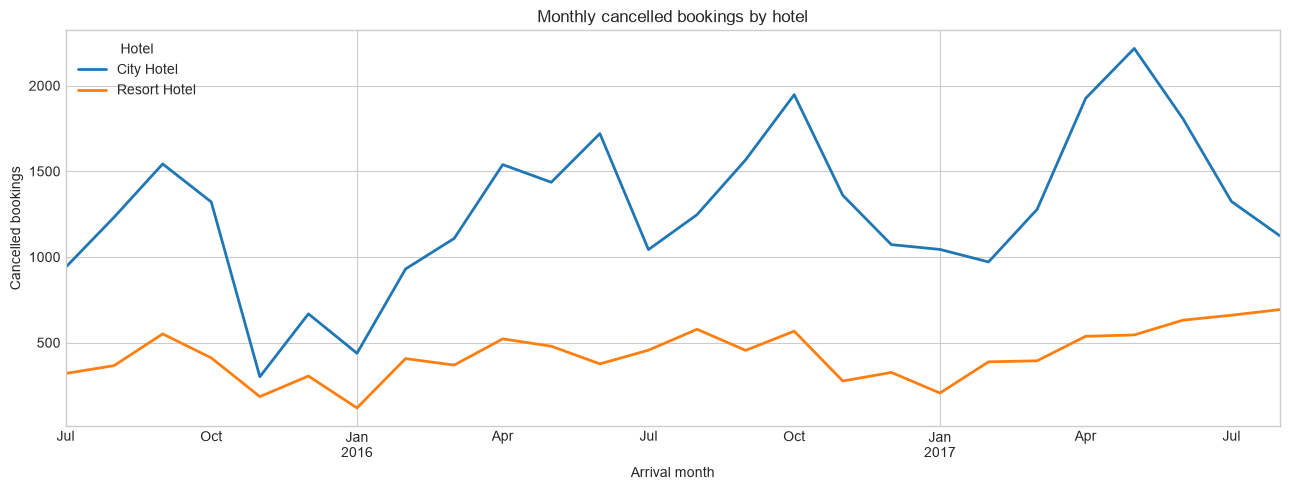

In [219]:
monthly_cancel_volume = bookings.groupby(["arrival_date", "hotel"])["is_canceled"].agg(bookings="size", cancelled="sum", cancellation_rate="mean").reset_index()
monthly_cancel_volume["cancellation_rate_pct"] = monthly_cancel_volume["cancellation_rate"] * 100
monthly_cancel_volume = monthly_cancel_volume.set_index("arrival_date").groupby("hotel").resample("MS").sum(numeric_only=True)
display(monthly_cancel_volume.head(12).round(2))
fig, ax = plt.subplots(figsize=(13, 5))
monthly_cancel_volume["cancelled"].unstack(level=0).plot(ax=ax, linewidth=2)
ax.set_title("Monthly cancelled bookings by hotel")
ax.set_xlabel("Arrival month")
ax.set_ylabel("Cancelled bookings")
ax.legend(title="Hotel")
fig.tight_layout()
plt.show()


## 43. Does cancellation risk differ by season?

We group arrival months into seasons to provide a simpler business summary than individual monthly rates.


,bookings,cancelled,cancellation_rate,cancellation_rate_pct
arrival_season,,,,
Winter,20777,6874,0.331,33.085
Spring,32674,12350,0.378,37.798
Summer,37477,14516,0.387,38.733
Autumn,28462,10484,0.368,36.835


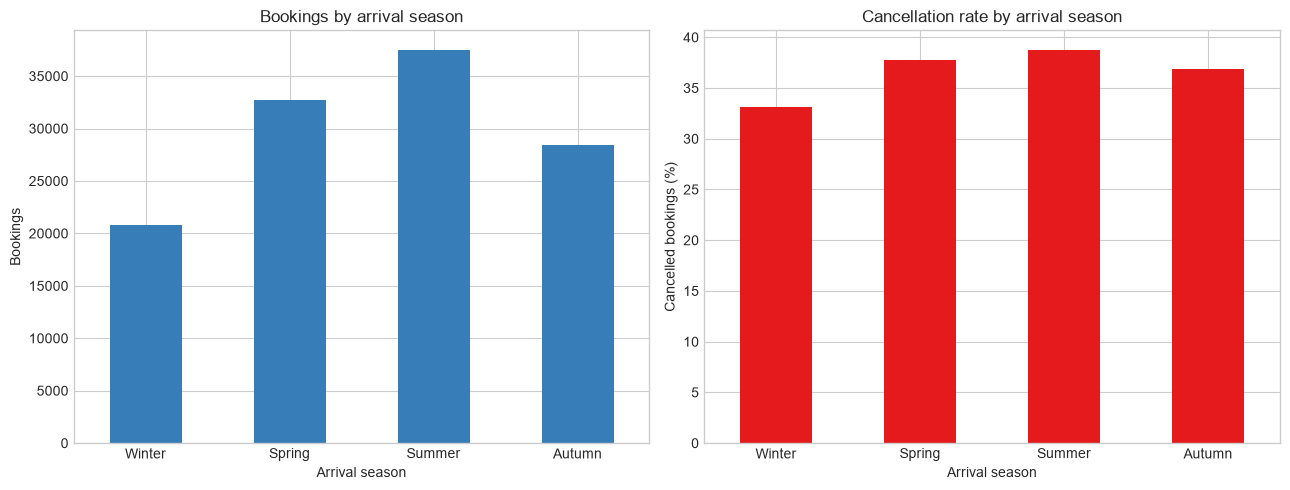

In [220]:
season_map = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring", 6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn"}
season_data = bookings.assign(arrival_season=bookings["arrival_month"].map(season_map))
season_summary = season_data.groupby("arrival_season")["is_canceled"].agg(bookings="size", cancelled="sum", cancellation_rate="mean").reindex(["Winter", "Spring", "Summer", "Autumn"])
season_summary["cancellation_rate_pct"] = season_summary["cancellation_rate"] * 100
display(season_summary.round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
season_summary["bookings"].plot.bar(ax=axes[0], color="#377eb8")
season_summary["cancellation_rate_pct"].plot.bar(ax=axes[1], color="#e41a1c")
axes[0].set_title("Bookings by arrival season")
axes[0].set_ylabel("Bookings")
axes[1].set_title("Cancellation rate by arrival season")
axes[1].set_ylabel("Cancelled bookings (%)")
for ax in axes:
    ax.set_xlabel("Arrival season")
    ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()


## 44. How does cancellation behavior change over booking year-month?

This time series can reveal broad changes in cancellation behavior across the available data period. It remains descriptive and does not replace the required chronological proof split.


C:\Users\aayus\AppData\Local\Temp\ipykernel_23144\1385036238.py:3: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(year_month_summary.head(12).round(3))


,arrival_date,hotel,bookings,cancelled,cancellation_rate,cancellation_rate_pct
0,2015-07-01,City Hotel,79,14,0.177,17.722
1,2015-07-01,Resort Hotel,43,5,0.116,11.628
2,2015-07-02,City Hotel,49,48,0.980,97.959
3,2015-07-02,Resort Hotel,44,9,0.205,20.455
4,2015-07-03,City Hotel,16,6,0.375,37.500
5,2015-07-03,Resort Hotel,40,13,0.325,32.500
6,2015-07-04,City Hotel,38,29,0.763,76.316
7,2015-07-04,Resort Hotel,50,14,0.280,28.000
8,2015-07-05,City Hotel,8,8,1.000,100.000
9,2015-07-05,Resort Hotel,45,8,0.178,17.778


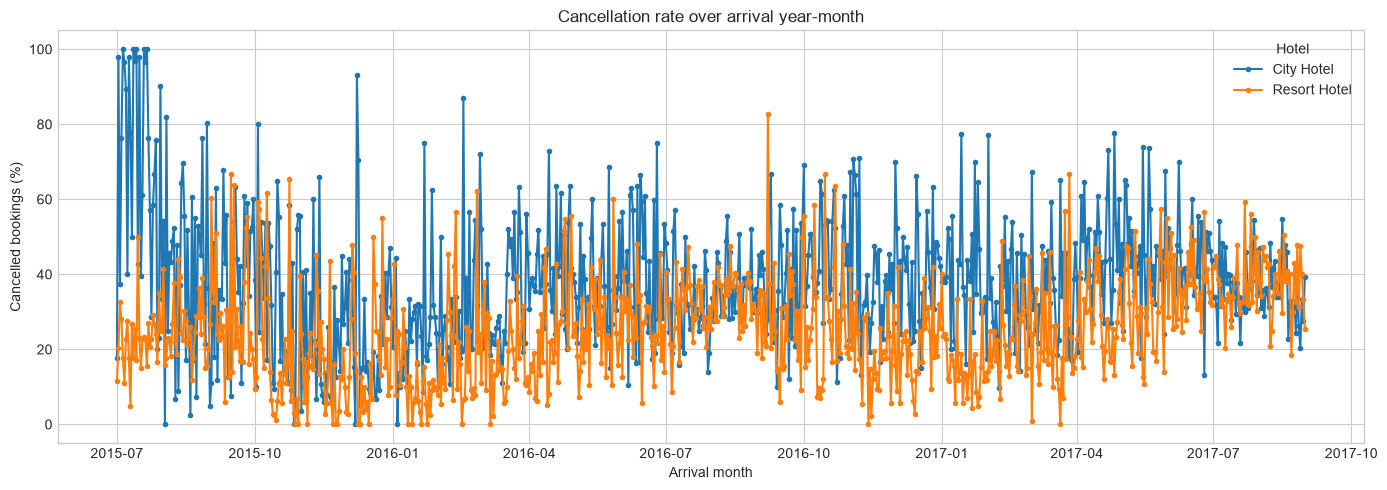

In [221]:
year_month_summary = bookings.groupby(["arrival_date", "hotel"])["is_canceled"].agg(bookings="size", cancelled="sum", cancellation_rate="mean").reset_index()
year_month_summary["cancellation_rate_pct"] = year_month_summary["cancellation_rate"] * 100
display(year_month_summary.head(12).round(3))
fig, ax = plt.subplots(figsize=(14, 5))
for hotel, group in year_month_summary.groupby("hotel"):
    ax.plot(group["arrival_date"], group["cancellation_rate_pct"], marker="o", markersize=3, linewidth=1.5, label=hotel)
ax.set_title("Cancellation rate over arrival year-month")
ax.set_xlabel("Arrival month")
ax.set_ylabel("Cancelled bookings (%)")
ax.legend(title="Hotel")
fig.tight_layout()
plt.show()


## 45. Connected cancellation drill-down

The earlier sections explored each factor separately. This final view connects them in the order a modeling question should be asked: start with the hotel-level difference, drill into lead time, add deposit commitment, then compare customer and channel groups. We finish by checking repeat guests and separating cancellation rate from cancellation volume.

The plots below reuse the summary tables already calculated above rather than creating unrelated charts at the end.


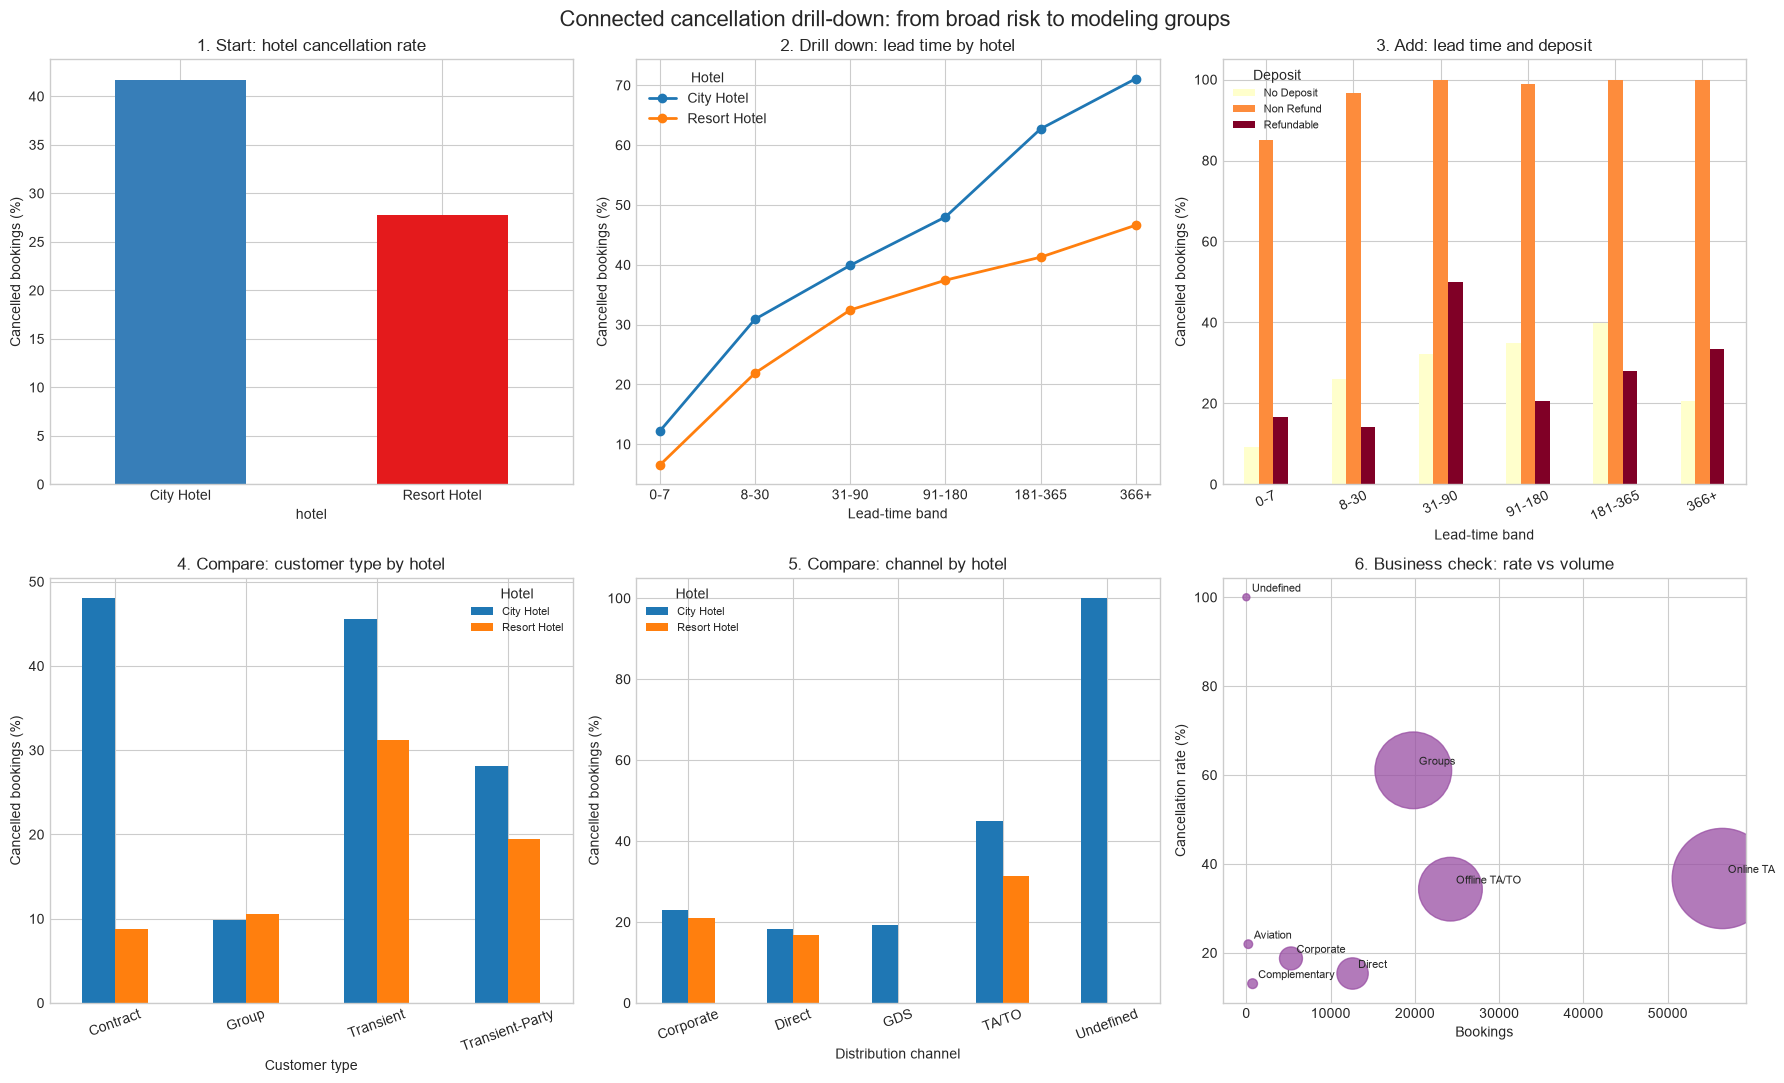

In [222]:
hotel_drilldown = bookings.groupby("hotel")["is_canceled"].agg(bookings="size", cancelled="sum", cancellation_rate="mean")
hotel_drilldown["cancellation_rate_pct"] = hotel_drilldown["cancellation_rate"] * 100

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
hotel_drilldown["cancellation_rate_pct"].plot.bar(ax=axes[0, 0], color=["#377eb8", "#e41a1c"])
axes[0, 0].set_title("1. Start: hotel cancellation rate")
axes[0, 0].set_ylabel("Cancelled bookings (%)")
axes[0, 0].tick_params(axis="x", rotation=0)

lead_hotel_summary["cancellation_rate_pct"].unstack().plot(ax=axes[0, 1], marker="o", linewidth=2)
axes[0, 1].set_title("2. Drill down: lead time by hotel")
axes[0, 1].set_xlabel("Lead-time band")
axes[0, 1].set_ylabel("Cancelled bookings (%)")
axes[0, 1].legend(title="Hotel")

lead_deposit_rates.plot.bar(ax=axes[0, 2], colormap="YlOrRd")
axes[0, 2].set_title("3. Add: lead time and deposit")
axes[0, 2].set_xlabel("Lead-time band")
axes[0, 2].set_ylabel("Cancelled bookings (%)")
axes[0, 2].tick_params(axis="x", rotation=25)
axes[0, 2].legend(title="Deposit", fontsize=8)

customer_hotel["cancellation_rate_pct"].unstack().plot.bar(ax=axes[1, 0])
axes[1, 0].set_title("4. Compare: customer type by hotel")
axes[1, 0].set_xlabel("Customer type")
axes[1, 0].set_ylabel("Cancelled bookings (%)")
axes[1, 0].tick_params(axis="x", rotation=20)
axes[1, 0].legend(title="Hotel", fontsize=8)

channel_hotel["cancellation_rate_pct"].unstack().plot.bar(ax=axes[1, 1])
axes[1, 1].set_title("5. Compare: channel by hotel")
axes[1, 1].set_xlabel("Distribution channel")
axes[1, 1].set_ylabel("Cancelled bookings (%)")
axes[1, 1].tick_params(axis="x", rotation=20)
axes[1, 1].legend(title="Hotel", fontsize=8)

axes[1, 2].scatter(volume_rate["bookings"], volume_rate["cancellation_rate_pct"], s=volume_rate["cancelled"] * 0.25 + 25, alpha=0.75, color="#984ea3")
for label, row in volume_rate.iterrows():
    axes[1, 2].annotate(label, (row["bookings"], row["cancellation_rate_pct"]), xytext=(4, 4), textcoords="offset points", fontsize=8)
axes[1, 2].set_title("6. Business check: rate vs volume")
axes[1, 2].set_xlabel("Bookings")
axes[1, 2].set_ylabel("Cancellation rate (%)")

fig.suptitle("Connected cancellation drill-down: from broad risk to modeling groups", fontsize=16)
fig.tight_layout()
plt.show()


## Conclusion: Modeling hypotheses

The EDA supports the following hypotheses to test with leakage-safe experiments:

- **Lead time:** cancellation behavior changes strongly across lead-time bands; lead time should be tested as a model predictor.
- **Deposit type:** deposit categories have very different cancellation behavior; deposit type should be tested, while checking category size and timing.
- **Hotel:** City Hotel and Resort Hotel have substantially different cancellation rates; hotel should be retained as a predictor or modeled separately.
- **Customer, segment, and channel:** customer type, market segment, and distribution channel show different cancellation patterns; their incremental value should be measured rather than assumed.
- **Repeat guests:** repeat guests cancel less often than new guests; repeat-guest status and prior booking history are candidates for testing.
- **Rate versus volume:** a group with the highest cancellation rate is not always responsible for the most cancellations; model evaluation must consider nightly business cost, not rate alone.

These are **modeling hypotheses, not causal conclusions**. We will test them using the chronological train, choose, and proof split. Only information available at booking time may enter the MVP, and proof-period results must not be used to tune the model or buffer.
